In [1]:
from google.colab import drive
from pathlib import Path
import zipfile
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import lightgbm as lgb
from sklearn.metrics import mean_absolute_error, mean_squared_error

In [2]:
#Mount our drive
drive.mount('/content/drive')

Mounted at /content/drive


In [3]:
Project_dir = Path("/content/drive/MyDrive/Walmart_M5_Forecasting")

Data = Project_dir / "data"
Raw = Data / "raw"
Processed = Data / "processed"
Reports = Project_dir / "reports"

for directory in [
    Raw,
    Processed,
    Reports,
]:
    directory.mkdir(parents=True, exist_ok=True)

print("Project directory:", Project_dir)
print("Raw data directory:", Raw)
print("Project directories created successfully.")

Project directory: /content/drive/MyDrive/Walmart_M5_Forecasting
Raw data directory: /content/drive/MyDrive/Walmart_M5_Forecasting/data/raw
Project directories created successfully.


In [4]:
#convert the files into individual callable files and analyse them.
calendar = pd.read_csv(
    Processed / "calendar.csv",
    parse_dates=["date"],
)

sales_val = pd.read_csv(
    Processed / "sales_train_validation.csv",
)

sales_eval = pd.read_csv(
    Processed / "sales_train_evaluation.csv",
)

prices = pd.read_csv(
    Processed / "sell_prices.csv",
)

submission = pd.read_csv(
    Processed / "sample_submission.csv",
)

datasets = {
    "calendar": calendar,
    "sales_train_validation": sales_val,
    "sales_train_evaluation": sales_eval,
    "sell_prices": prices,
    "sample_submission": submission,
}

for name, df in datasets.items():
    print(f"\n{'=' * 60}")
    print(name)
    print(f"Shape: {df.shape}")
    print(f"Duplicate rows: {df.duplicated().sum()}")
    print(f"Missing cells: {df.isna().sum().sum()}")

print("\nCalendar date range:")
print(calendar["date"].min(), "to", calendar["date"].max())

print("\nSales time-series columns:")
day_columns = [
    col for col in sales_val.columns
    if col.startswith("d_")
]
print("First:", day_columns[0])
print("Last:", day_columns[-1])
print("Number of daily observations:", len(day_columns))

print("\nCalendar event and identifier columns:")
print(calendar.columns.tolist())

print("\nSales identifiers:")
print(sales_val[
    ["item_id", "dept_id", "cat_id", "store_id", "state_id"]
].nunique())

print("\nPrice identifiers:")
print(prices[["store_id", "item_id", "wm_yr_wk"]].nunique())



calendar
Shape: (1969, 14)
Duplicate rows: 0
Missing cells: 7542

sales_train_validation
Shape: (30490, 1919)
Duplicate rows: 0
Missing cells: 0

sales_train_evaluation
Shape: (30490, 1947)
Duplicate rows: 0
Missing cells: 0

sell_prices
Shape: (6841121, 4)
Duplicate rows: 0
Missing cells: 0

sample_submission
Shape: (60980, 29)
Duplicate rows: 0
Missing cells: 0

Calendar date range:
2011-01-29 00:00:00 to 2016-06-19 00:00:00

Sales time-series columns:
First: d_1
Last: d_1913
Number of daily observations: 1913

Calendar event and identifier columns:
['date', 'wm_yr_wk', 'weekday', 'wday', 'month', 'year', 'd', 'event_name_1', 'event_type_1', 'event_name_2', 'event_type_2', 'snap_CA', 'snap_TX', 'snap_WI']

Sales identifiers:
item_id     3049
dept_id        7
cat_id         3
store_id      10
state_id       3
dtype: int64

Price identifiers:
store_id      10
item_id     3049
wm_yr_wk     282
dtype: int64


In [ ]:
#Data integrity.

# 1. Define the identifier columns
series_keys = ["item_id", "store_id"]
price_keys = ["store_id", "item_id", "wm_yr_wk"]

# 2. Check uniqueness of identifiers
print("=" * 60)
print("A. IDENTIFIER INTEGRITY")
print("=" * 60)

print("Validation sales:")
print("  Duplicate item-store series:",
      sales_val.duplicated(series_keys).sum())

print("Evaluation sales:")
print("  Duplicate item-store series:",
      sales_eval.duplicated(series_keys).sum())

print("Calendar:")
print("  Duplicate dates:", calendar["date"].duplicated().sum())
print("  Duplicate day IDs:", calendar["d"].duplicated().sum())

print("Prices:")
print("  Duplicate store-item-week keys:",
      prices.duplicated(price_keys).sum())

# Check whether the same item-store series exist in both sales files
validation_ids = set(
    map(tuple, sales_val[series_keys].to_numpy())
)
evaluation_ids = set(
    map(tuple, sales_eval[series_keys].to_numpy())
)

print("  Series in validation but not evaluation:",
      len(validation_ids - evaluation_ids))
print("  Series in evaluation but not validation:",
      len(evaluation_ids - validation_ids))


# 3. Check the sales day columns
print("\n" + "=" * 60)
print("B. SALES DAY-COLUMN INTEGRITY")
print("=" * 60)

def day_columns(df):
    return [
        col for col in df.columns
        if col.startswith("d_") and col[2:].isdigit()
    ]

val_days = day_columns(sales_val)
eval_days = day_columns(sales_eval)

print("Validation sales:")
print("  First day:", val_days[0], "| Last day:", val_days[-1])
print("  Number of daily columns:", len(val_days))

print("Evaluation sales:")
print("  First day:", eval_days[0], "| Last day:", eval_days[-1])
print("  Number of daily columns:", len(eval_days))

# 4. Verify that calendar day IDs map to consecutive dates
calendar_check = calendar.copy()
calendar_check["date"] = pd.to_datetime(calendar_check["date"])
calendar_check["day_number"] = (
    calendar_check["d"].str.extract(r"d_(\d+)")[0].astype(int)
)

calendar_check = calendar_check.sort_values("day_number").reset_index(drop=True)

expected_day_numbers = list(range(1, len(calendar_check) + 1))
actual_day_numbers = calendar_check["day_number"].tolist()

print("\nCalendar day IDs consecutive:",
      actual_day_numbers == expected_day_numbers)
print("Calendar dates strictly increasing:",
      calendar_check["date"].is_monotonic_increasing)
print("Calendar date gaps other than one day:",
      (calendar_check["date"].diff().dropna() != pd.Timedelta(days=1)).sum())

# Display key forecast boundaries
day_lookup = calendar_check.set_index("d")["date"]

for label, day_id in [
    ("Last training day", "d_1913"),
    ("Last validation target day", "d_1941"),
    ("Last evaluation target day", "d_1969"),
]:
    if day_id in day_lookup.index:
        print(f"{label} ({day_id}): {day_lookup.loc[day_id].date()}")
    else:
        print(f"{label} ({day_id}): NOT FOUND IN CALENDAR")


# 5. Inspect calendar missingness by column
print("\n" + "=" * 60)
print("C. CALENDAR MISSINGNESS")
print("=" * 60)

missing = calendar.isna().sum()
missing = missing[missing > 0].sort_values(ascending=False)

if missing.empty:
    print("No missing calendar values.")
else:
    print("Missing cells by column:")
    print(missing.to_string())

    event_columns = [
        col for col in calendar.columns
        if "event_name" in col or "event_type" in col
    ]
    print("\nMissing counts in event-related columns:")
    print(calendar[event_columns].isna().sum().to_string())


# 6. Check target values and negative sales
print("\n" + "=" * 60)
print("D. SALES TARGET SANITY CHECK")
print("=" * 60)

for label, df, days in [
    ("Validation sales", sales_val, val_days),
    ("Evaluation sales", sales_eval, eval_days),
]:
    values = df[days]

    print(f"\n{label}:")
    print("  Missing sales values:", int(values.isna().sum().sum()))
    print("  Negative sales values:", int((values < 0).sum().sum()))
    print("  Total units sold:", int(values.sum().sum()))
    print("  Zero-sales observations:", int((values == 0).sum().sum()))

A. IDENTIFIER INTEGRITY
Validation sales:
  Duplicate item-store series: 0
Evaluation sales:
  Duplicate item-store series: 0
Calendar:
  Duplicate dates: 0
  Duplicate day IDs: 0
Prices:
  Duplicate store-item-week keys: 0
  Series in validation but not evaluation: 0
  Series in evaluation but not validation: 0

B. SALES DAY-COLUMN INTEGRITY
Validation sales:
  First day: d_1 | Last day: d_1913
  Number of daily columns: 1913
Evaluation sales:
  First day: d_1 | Last day: d_1941
  Number of daily columns: 1941

Calendar day IDs consecutive: True
Calendar dates strictly increasing: True
Calendar date gaps other than one day: 0
Last training day (d_1913): 2016-04-24
Last validation target day (d_1941): 2016-05-22
Last evaluation target day (d_1969): 2016-06-19

C. CALENDAR MISSINGNESS
Missing cells by column:
event_type_2    1964
event_name_2    1964
event_type_1    1807
event_name_1    1807

Missing counts in event-related columns:
event_name_1    1807
event_type_1    1807
event_name_2

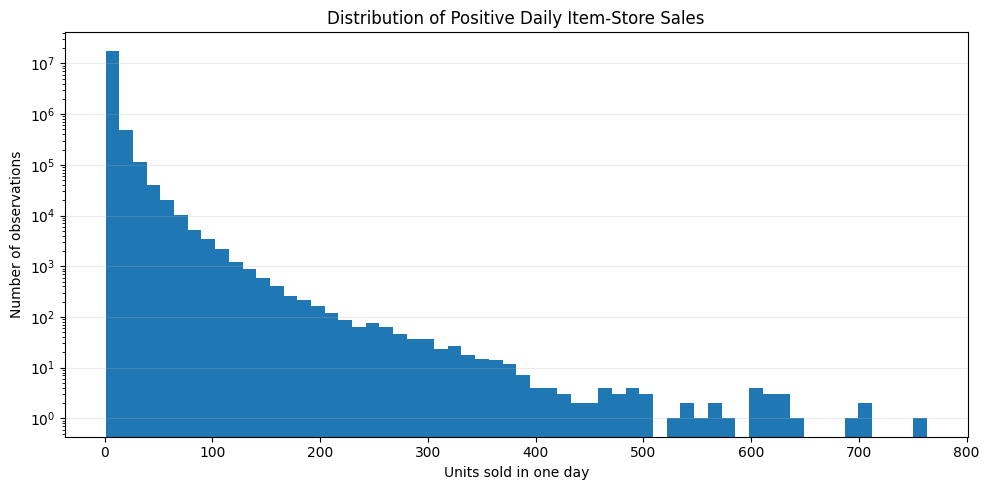

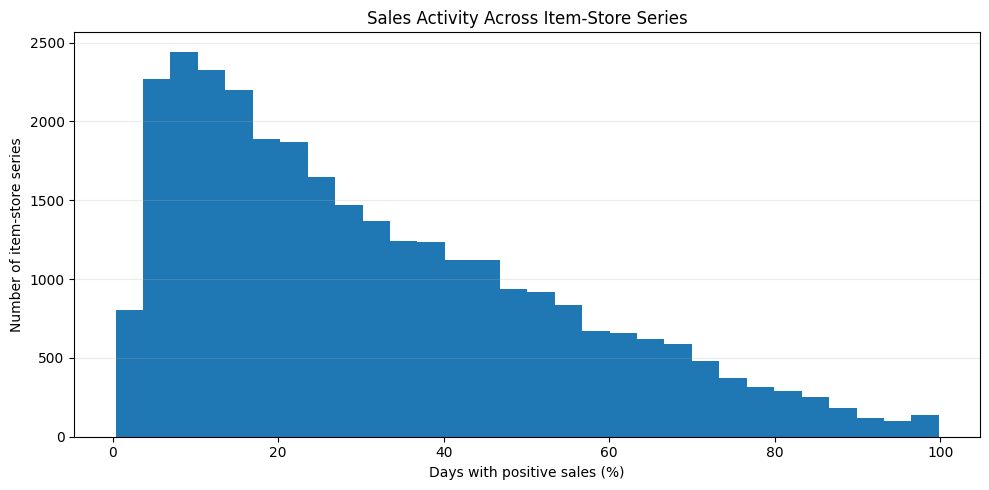

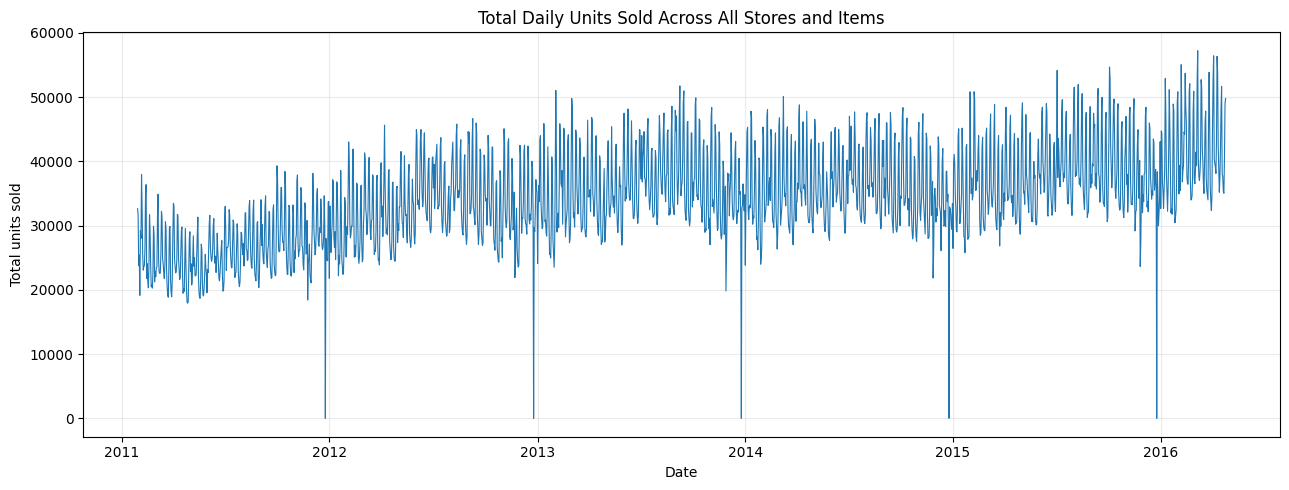

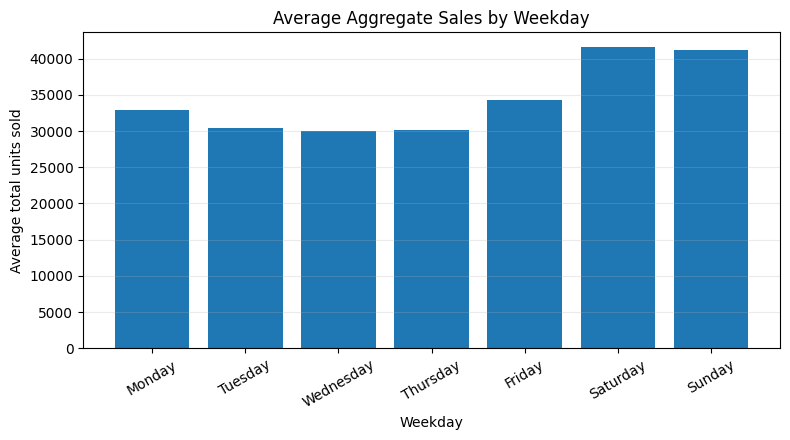

In [ ]:
# 1. Prepare the sales data

day_cols = [
    c for c in sales_val.columns
    if c.startswith("d_") and c[2:].isdigit()
]

sales = sales_val[day_cols]
sales_array = sales.to_numpy()

# Map day IDs to actual dates
calendar_dates = (
    calendar.assign(date=pd.to_datetime(calendar["date"]))
    .set_index("d")["date"]
)

dates = calendar_dates.loc[day_cols].to_numpy()

# Series-level statistics
series_total = sales.sum(axis=1)
active_days = (sales > 0).sum(axis=1)
active_day_share = active_days / len(day_cols)

# Aggregate demand across all item-store series
daily_total = sales.sum(axis=0).to_numpy()

daily_summary = pd.DataFrame({
    "date": pd.to_datetime(dates),
    "total_units_sold": daily_total
})

daily_summary["weekday"] = daily_summary["date"].dt.day_name()

weekday_order = [
    "Monday", "Tuesday", "Wednesday", "Thursday",
    "Friday", "Saturday", "Sunday"
]


# 2. Plot 1: Distribution of daily item-store sales

fig, ax = plt.subplots(figsize=(10, 5))

positive_sales = sales_array[sales_array > 0]

ax.hist(positive_sales, bins=60)
ax.set_title("Distribution of Positive Daily Item-Store Sales")
ax.set_xlabel("Units sold in one day")
ax.set_ylabel("Number of observations")
ax.set_yscale("log")
ax.grid(axis="y", alpha=0.25)

plt.tight_layout()
plt.show()


# 3. Plot 2: How often does each series sell?

fig, ax = plt.subplots(figsize=(10, 5))

ax.hist(active_day_share * 100, bins=30)
ax.set_title("Sales Activity Across Item-Store Series")
ax.set_xlabel("Days with positive sales (%)")
ax.set_ylabel("Number of item-store series")
ax.grid(axis="y", alpha=0.25)

plt.tight_layout()
plt.show()


# 4. Plot 3: Total daily demand over time

fig, ax = plt.subplots(figsize=(13, 5))

ax.plot(
    daily_summary["date"],
    daily_summary["total_units_sold"],
    linewidth=0.8
)

ax.set_title("Total Daily Units Sold Across All Stores and Items")
ax.set_xlabel("Date")
ax.set_ylabel("Total units sold")
ax.grid(alpha=0.25)

plt.tight_layout()
plt.show()


# 5. Plot 4: Average sales by weekday

weekday_means = (
    daily_summary.groupby("weekday")["total_units_sold"]
    .mean()
    .reindex(weekday_order)
)

fig, ax = plt.subplots(figsize=(8, 4.5))

ax.bar(weekday_means.index, weekday_means.values)
ax.set_title("Average Aggregate Sales by Weekday")
ax.set_xlabel("Weekday")
ax.set_ylabel("Average total units sold")
ax.tick_params(axis="x", rotation=30)
ax.grid(axis="y", alpha=0.25)

plt.tight_layout()
plt.show()


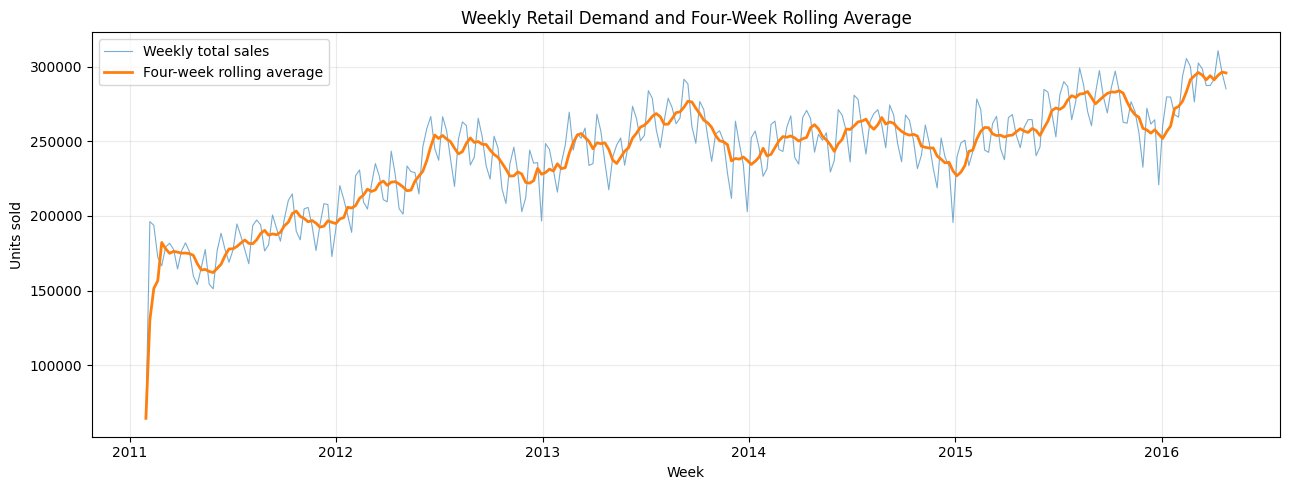

In [ ]:
# Uses the daily_summary dataframe from our earlier EDA cell to plot weekly aggregate demand alongside a four-week rolling average.
# It will help distinguish recurring short-term fluctuations from the longer-term trend.
weekly = (
    daily_summary
    .set_index("date")["total_units_sold"]
    .resample("W")
    .sum()
)

rolling_4w = weekly.rolling(4, min_periods=1).mean()

fig, ax = plt.subplots(figsize=(13, 5))

ax.plot(
    weekly.index, weekly.values,
    linewidth=0.8, alpha=0.6, label="Weekly total sales"
)
ax.plot(
    rolling_4w.index, rolling_4w.values,
    linewidth=2, label="Four-week rolling average"
)

ax.set_title("Weekly Retail Demand and Four-Week Rolling Average")
ax.set_xlabel("Week")
ax.set_ylabel("Units sold")
ax.legend()
ax.grid(alpha=0.25)

plt.tight_layout()
plt.show()


Training series: 30490
History window: d_1886–d_1913
Forecast window: d_1914–d_1941
Actual target shape: (30490, 28)

OVERALL VALIDATION RESULTS
                              MAE    RMSE   WAPE (%)  Bias (units)
Naive                      1.3730  2.8936  95.162102        0.1903
Seasonal naive (7-day)     1.2440  2.6769  86.218102       -0.1062
Four-week weekday average  1.1037  2.3140  76.492897       -0.0564

RESULTS BY DEMAND FREQUENCY
                         Demand group                     Model    MAE   RMSE   WAPE (%)  Series
Very intermittent (<=10% active days)                     Naive 0.4372 0.9739 149.576797    5284
Very intermittent (<=10% active days)    Seasonal naive (7-day) 0.4011 0.9376 137.210403    5284
Very intermittent (<=10% active days) Four-week weekday average 0.3810 0.7874 130.341507    5284
           Intermittent (>10% to 30%)                     Naive 0.8682 1.6867 127.998199   11545
           Intermittent (>10% to 30%)    Seasonal naive (7-day) 0.7865 1.

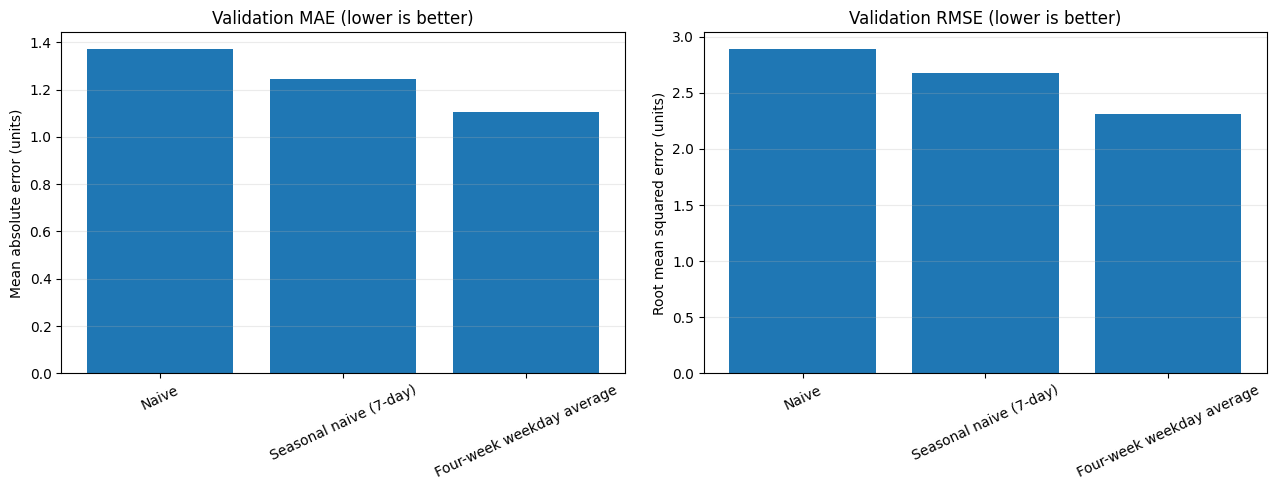

In [12]:
# Define the training history and validation target

KEYS = ["item_id", "store_id"]
HORIZON = 28

train_day_cols = [
    f"d_{i}" for i in range(1, 1914)
]
target_cols = [
    f"d_{i}" for i in range(1914, 1942)
]
history_cols = [
    f"d_{i}" for i in range(1886, 1914)
]

# Confirm required columns exist
assert all(c in sales_val.columns for c in train_day_cols)
assert all(c in sales_eval.columns for c in target_cols)

# Align evaluation rows with training rows by item and store
train_ids = pd.MultiIndex.from_frame(
    sales_val[KEYS]
)

evaluation_indexed = sales_eval.set_index(KEYS)

assert train_ids.is_unique
assert evaluation_indexed.index.is_unique
assert train_ids.isin(evaluation_indexed.index).all()

actual = evaluation_indexed.loc[
    train_ids, target_cols
].to_numpy(dtype=np.float32)

# Only the final 28 training days are needed for these baselines
history = sales_val[
    history_cols
].to_numpy(dtype=np.float32)

assert history.shape[1] == HORIZON
assert actual.shape == (len(sales_val), HORIZON)

print("Training series:", len(sales_val))
print("History window: d_1886–d_1913")
print("Forecast window: d_1914–d_1941")
print("Actual target shape:", actual.shape)


# Generate the three forecasts

# Baseline 1: repeat the most recent day's sales
naive_pred = np.repeat(
    history[:, -1:],
    HORIZON,
    axis=1
)

# Baseline 2: repeat the last seven days four times
seasonal_naive_pred = np.tile(
    history[:, -7:],
    (1, 4)
)

# Baseline 3: average each weekday across the last four weeks
# Reshape to: series x week x weekday
four_weeks = history.reshape(-1, 4, 7)

weekday_means = four_weeks.mean(axis=1)

four_week_pred = np.tile(
    weekday_means,
    (1, 4)
)

predictions = {
    "Naive": naive_pred,
    "Seasonal naive (7-day)": seasonal_naive_pred,
    "Four-week weekday average": four_week_pred,
}


# Evaluate forecast errors

def calculate_metrics(y_true, y_pred):
    errors = y_pred - y_true

    return {
        "MAE": np.abs(errors).mean(),
        "RMSE": np.sqrt(np.square(errors).mean()),
        "WAPE (%)": (
            np.abs(errors).sum() / y_true.sum() * 100
            if y_true.sum() > 0 else np.nan
        ),
        "Bias (units)": errors.mean(),
    }


overall_results = pd.DataFrame({
    name: calculate_metrics(actual, pred)
    for name, pred in predictions.items()
}).T

print("\nOVERALL VALIDATION RESULTS")
print(overall_results.round(4).to_string())


# Compare performance by demand frequency

# Calculate the percentage of training days with positive sales
active_share = (
    sales_val[train_day_cols]
    .gt(0)
    .mean(axis=1)
    .to_numpy()
)

frequency_groups = {
    "Very intermittent (<=10% active days)": active_share <= 0.10,
    "Intermittent (>10% to 30%)": (
        (active_share > 0.10) & (active_share <= 0.30)
    ),
    "More regular (>30%)": active_share > 0.30,
}

group_rows = []

for group_name, mask in frequency_groups.items():
    for model_name, pred in predictions.items():
        metrics = calculate_metrics(actual[mask], pred[mask])
        group_rows.append({
            "Demand group": group_name,
            "Model": model_name,
            "MAE": metrics["MAE"],
            "RMSE": metrics["RMSE"],
            "WAPE (%)": metrics["WAPE (%)"],
            "Series": int(mask.sum()),
        })

group_results = pd.DataFrame(group_rows)

print("\nRESULTS BY DEMAND FREQUENCY")
print(
    group_results.round(4)
    .to_string(index=False)
)



#  Visualise overall model comparison

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

model_names = overall_results.index.tolist()

axes[0].bar(model_names, overall_results["MAE"])
axes[0].set_title("Validation MAE (lower is better)")
axes[0].set_ylabel("Mean absolute error (units)")
axes[0].tick_params(axis="x", rotation=25)
axes[0].grid(axis="y", alpha=0.25)

axes[1].bar(model_names, overall_results["RMSE"])
axes[1].set_title("Validation RMSE (lower is better)")
axes[1].set_ylabel("Root mean squared error (units)")
axes[1].tick_params(axis="x", rotation=25)
axes[1].grid(axis="y", alpha=0.25)

plt.tight_layout()
plt.show()


VALIDATION RESULTS BY STORE
Store                     Model  Series  Actual units   MAE  RMSE   WAPE (%)  Bias (units)
 CA_1                     Naive    3049        134032 1.568 3.055  99.860001         0.435
 CA_1    Seasonal naive (7-day)    3049        134032 1.363 2.737  86.802002        -0.087
 CA_1 Four-week weekday average    3049        134032 1.202 2.377  76.565002        -0.071
 CA_2                     Naive    3049        132920 1.625 3.011 104.397003         0.438
 CA_2    Seasonal naive (7-day)    3049        132920 1.363 2.566  87.570000        -0.110
 CA_2 Four-week weekday average    3049        132920 1.192 2.167  76.537003        -0.092
 CA_3                     Naive    3049        175360 1.881 3.689  91.578003         0.478
 CA_3    Seasonal naive (7-day)    3049        175360 1.650 3.316  80.310997        -0.050
 CA_3 Four-week weekday average    3049        175360 1.457 2.916  70.924004         0.019
 CA_4                     Naive    3049         78858 1.042 2.

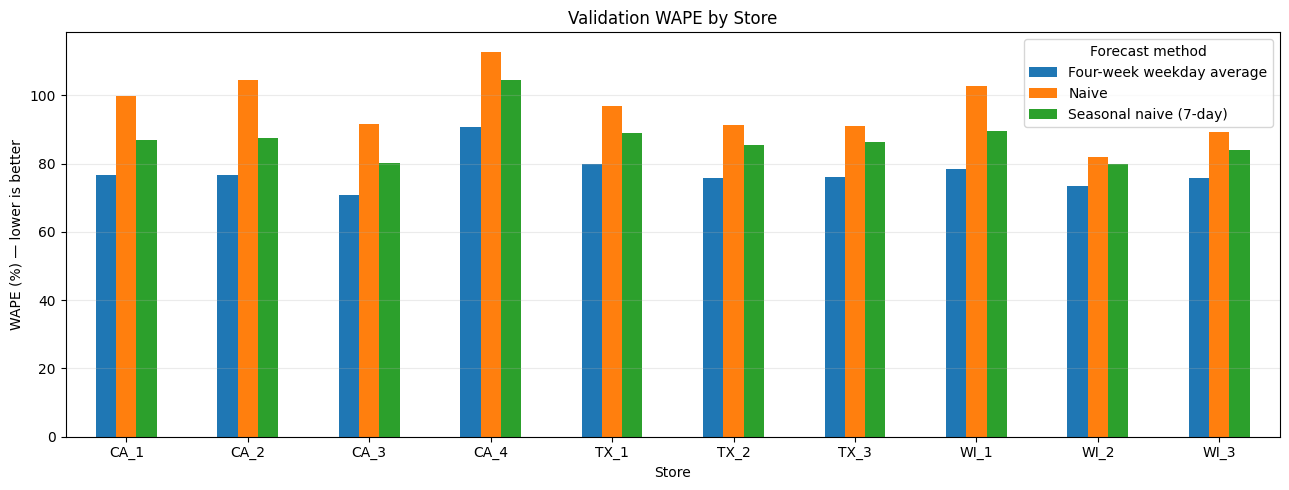

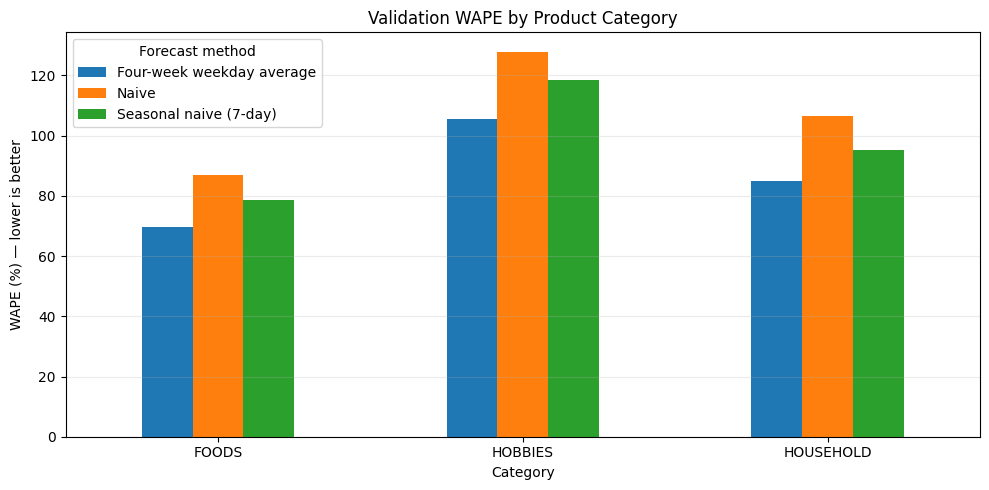

In [ ]:
#Demand and perstore analysis

KEYS = ["item_id", "store_id"]
CATEGORY_KEY = "cat_id"

# Align product metadata to the same series order used in validation.
metadata = sales_val[
    KEYS + [CATEGORY_KEY]
].copy()

assert len(metadata) == len(actual)
assert metadata[KEYS].equals(
    sales_val[KEYS].reset_index(drop=True)
)

def grouped_metrics(group_column, group_name):
    rows = []

    for group_value, positions in metadata.groupby(
        group_column, sort=True
    ).indices.items():

        positions = np.asarray(positions)

        y_true = actual[positions]
        group_total = y_true.sum()

        for model_name, y_pred in predictions.items():
            y_hat = y_pred[positions]
            errors = y_hat - y_true

            rows.append({
                group_name: group_value,
                "Model": model_name,
                "Series": len(positions),
                "Actual units": int(group_total),
                "MAE": np.abs(errors).mean(),
                "RMSE": np.sqrt(np.square(errors).mean()),
                "WAPE (%)": (
                    np.abs(errors).sum() / group_total * 100
                    if group_total > 0 else np.nan
                ),
                "Bias (units)": errors.mean(),
            })

    return pd.DataFrame(rows)


# 1. Compare the methods across stores.
store_results = grouped_metrics("store_id", "Store")

print("VALIDATION RESULTS BY STORE")
print(
    store_results.round(3).to_string(index=False)
)

# 2. Compare the methods across product categories.
category_results = grouped_metrics("cat_id", "Category")

print("\nVALIDATION RESULTS BY CATEGORY")
print(
    category_results.round(3).to_string(index=False)
)

# 3. Focus on improvement from seasonal naive to weekday average.
def compare_improvement(results, group_column):
    wide = results.pivot(
        index=group_column,
        columns="Model",
        values=["MAE", "RMSE", "WAPE (%)"]
    )

    rows = []
    for group in wide.index:
        naive_wape = wide.loc[
            group, ("WAPE (%)", "Seasonal naive (7-day)")
        ]
        weekday_wape = wide.loc[
            group, ("WAPE (%)", "Four-week weekday average")
        ]

        rows.append({
            group_column: group,
            "Seasonal naive WAPE (%)": naive_wape,
            "Weekday average WAPE (%)": weekday_wape,
            "WAPE improvement (%)": (
                (naive_wape - weekday_wape) / naive_wape * 100
                if naive_wape > 0 else np.nan
            ),
        })

    return pd.DataFrame(rows)


print("\nWAPE IMPROVEMENT BY STORE")
print(
    compare_improvement(store_results, "Store")
    .round(2)
    .to_string(index=False)
)

print("\nWAPE IMPROVEMENT BY CATEGORY")
print(
    compare_improvement(category_results, "Category")
    .round(2)
    .to_string(index=False)
)

# 4. Visualise the strongest comparison: WAPE by store.
plot_data = store_results.pivot(
    index="Store",
    columns="Model",
    values="WAPE (%)"
)

plot_data.plot(kind="bar", figsize=(13, 5))
plt.title("Validation WAPE by Store")
plt.ylabel("WAPE (%) — lower is better")
plt.xlabel("Store")
plt.xticks(rotation=0)
plt.grid(axis="y", alpha=0.25)
plt.legend(title="Forecast method")
plt.tight_layout()
plt.show()

# 5. Visualise WAPE by category.
plot_data = category_results.pivot(
    index="Category",
    columns="Model",
    values="WAPE (%)"
)

plot_data.plot(kind="bar", figsize=(10, 5))
plt.title("Validation WAPE by Product Category")
plt.ylabel("WAPE (%) — lower is better")
plt.xlabel("Category")
plt.xticks(rotation=0)
plt.grid(axis="y", alpha=0.25)
plt.legend(title="Forecast method")
plt.tight_layout()
plt.show()

In [13]:

# Confirm that the required objects from our previous milestone exist.
required_objects = [
    "sales_val",
    "sales_eval",
    "calendar",
    "prices",
    "actual",
    "predictions",
]

missing = [
    name for name in required_objects
    if name not in globals()
]

if missing:
    raise NameError(
        f"Missing required objects: {missing}. "
        "Run the relevant earlier notebook cells first."
    )

KEYS = ["item_id", "store_id"]
HORIZON = 28

# Verify unique series identifiers.
assert not sales_val.duplicated(KEYS).any()
assert not sales_eval.duplicated(KEYS).any()

# Verify the history and validation target dimensions.
assert actual.shape == (len(sales_val), HORIZON)
assert all(
    f"d_{i}" in sales_val.columns
    for i in range(1, 1914)
)
assert all(
    f"d_{i}" in sales_eval.columns
    for i in range(1914, 1942)
)

# Check the current baseline is still available.
assert "Four-week weekday average" in predictions

print("Environment checks passed.")
print("Series:", len(sales_val))
print("Available training days:", 1913)
print("Validation horizon:", HORIZON)
print("Baseline WAPE: 76.49%")

Environment checks passed.
Series: 30490
Available training days: 1913
Validation horizon: 28
Baseline WAPE: 76.49%


In [ ]:
# Use the most recent 56 observed days for the initial feature audit.
sales_cols = [f"d_{i}" for i in range(1, 1914)]

sales = sales_val[sales_cols].to_numpy(
    dtype=np.float32
)

# Each row represents one item-store series.
# Forecast origin: immediately after d_1913.
features = sales_val[KEYS].copy()

# Calendar features for the first validation day, d_1914.
# We'll attach the actual calendar mapping rather than infer weekdays
# from day IDs.
calendar_map = calendar.set_index("d")

target_day = "d_1914"
target_calendar = calendar_map.loc[target_day]

features["target_day"] = target_day
features["day_of_week"] = target_calendar["wday"]
features["month"] = target_calendar["month"]
features["year"] = target_calendar["year"]

# Historical sales lags measured relative to the forecast origin.
for lag in [1, 7, 14, 28]:
    features[f"lag_{lag}"] = sales[:, -lag]

# Rolling averages must use observed days only.
# The last observed day is d_1913.
for window in [7, 14, 28]:
    features[f"rolling_mean_{window}"] = (
        sales[:, -window:].mean(axis=1)
    )

# Useful descriptive metadata already included in the sales table.
metadata_cols = [
    c for c in [
        "dept_id", "cat_id", "state_id"
    ]
    if c in sales_val.columns
]

for col in metadata_cols:
    features[col] = sales_val[col].to_numpy()

assert len(features) == len(sales_val)
assert not features[KEYS].duplicated().any()
assert features.isna().sum().sum() == 0

print("Feature table shape:", features.shape)
print("\nFeature columns:")
print(features.columns.tolist())

print("\nFeature sample:")
print(features.head().to_string(index=False))

print("\nNumeric feature summary:")
print(
    features.select_dtypes(include=np.number)
    .describe()
    .round(3)
    .to_string()
)

Feature table shape: (30490, 16)

Feature columns:
['item_id', 'store_id', 'target_day', 'day_of_week', 'month', 'year', 'lag_1', 'lag_7', 'lag_14', 'lag_28', 'rolling_mean_7', 'rolling_mean_14', 'rolling_mean_28', 'dept_id', 'cat_id', 'state_id']

Feature sample:
      item_id store_id target_day  day_of_week  month  year  lag_1  lag_7  lag_14  lag_28  rolling_mean_7  rolling_mean_14  rolling_mean_28   dept_id  cat_id state_id
HOBBIES_1_001     CA_1     d_1914            3      4  2016    1.0    1.0     0.0     1.0        1.142857         0.928571         0.964286 HOBBIES_1 HOBBIES       CA
HOBBIES_1_002     CA_1     d_1914            3      4  2016    0.0    0.0     0.0     1.0        0.142857         0.071429         0.071429 HOBBIES_1 HOBBIES       CA
HOBBIES_1_003     CA_1     d_1914            3      4  2016    1.0    1.0     0.0     0.0        0.857143         1.000000         0.571429 HOBBIES_1 HOBBIES       CA
HOBBIES_1_004     CA_1     d_1914            3      4  2016    2.0 

In [6]:

# 1. Prepare historical sales and series metadata

sales_cols = [f"d_{i}" for i in range(1, 1914)]

sales = sales_val[sales_cols].to_numpy(
    dtype=np.float32
)

n_series, n_days = sales.shape

# Encode identifiers as compact integer codes.
# These will be supplied to LightGBM as categorical features.
metadata = pd.DataFrame(index=sales_val.index)

for col in ["item_id", "store_id", "dept_id", "cat_id", "state_id"]:
    metadata[col] = pd.Categorical(
        sales_val[col]
    ).codes.astype(np.int16)

categorical_features = [
    "item_id", "store_id", "dept_id", "cat_id", "state_id"
]

#  Select historical forecast origins

# One training example predicts sales for day k.
# Its features use sales only through day k-1.
#
# Approximately the most recent year, sampled every
# three days to cover different weekdays.

forecast_origins = list(range(1549, 1914, 3))

assert forecast_origins
assert min(forecast_origins) > 28
assert max(forecast_origins) <= 1913

calendar_map = calendar.set_index("d")

feature_blocks = []

# Construct leakage-safe examples

for k in forecast_origins:

    target_day = f"d_{k}"
    target_calendar = calendar_map.loc[target_day]

    # For target d_k, the latest known sales are through d_(k-1).
    history_end = k - 1  # Exclusive array index

    block = metadata.copy()

    # Calendar information for the day being predicted
    block["day_of_week"] = np.int8(target_calendar["wday"])
    block["month"] = np.int8(target_calendar["month"])
    block["year"] = np.int16(target_calendar["year"])

    # Lag features
    block["lag_1"] = sales[:, k - 2]
    block["lag_7"] = sales[:, k - 8]
    block["lag_14"] = sales[:, k - 15]
    block["lag_28"] = sales[:, k - 29]

    # Rolling statistics use past observations only.
    block["rolling_mean_7"] = sales[:, history_end - 7:history_end].mean(axis=1)
    block["rolling_mean_14"] = sales[:, history_end - 14:history_end].mean(axis=1)
    block["rolling_mean_28"] = sales[:, history_end - 28:history_end].mean(axis=1)

    # Actual sales on the target day become the training label.
    block["target"] = sales[:, k - 1]

    feature_blocks.append(block)

# Combine all forecast origins
train_table = pd.concat(feature_blocks, ignore_index=True)

feature_cols = [
    "item_id", "store_id", "dept_id", "cat_id", "state_id",
    "day_of_week", "month", "year",
    "lag_1", "lag_7", "lag_14", "lag_28",
    "rolling_mean_7", "rolling_mean_14", "rolling_mean_28"
]

X_train = train_table[feature_cols]
y_train = train_table["target"]

#  Audit the resulting training table

expected_rows = n_series * len(forecast_origins)

assert len(train_table) == expected_rows
assert X_train.isna().sum().sum() == 0
assert y_train.isna().sum() == 0
assert (y_train >= 0).all()

# Check the first training origin's alignment
first_k = forecast_origins[0]

np.testing.assert_array_equal(
    train_table.loc[:n_series - 1, "lag_1"].to_numpy(),
    sales[:, first_k - 2]
)

np.testing.assert_array_equal(
    y_train.iloc[:n_series].to_numpy(),
    sales[:, first_k - 1]
)

print("TRAINING TABLE AUDIT")
print("-" * 40)
print("Sales series:", n_series)
print("Historical forecast origins:", len(forecast_origins))
print("First target day:", f"d_{forecast_origins[0]}")
print("Last target day:", f"d_{forecast_origins[-1]}")
print("Feature matrix shape:", X_train.shape)
print("Target shape:", y_train.shape)
print(f"Training table memory: {train_table.memory_usage(deep=True).sum() / 1024**2:.1f} MB")
print("Missing feature values:", X_train.isna().sum().sum())
print("Missing targets:", y_train.isna().sum())
print("Minimum target:", y_train.min())
print("Maximum target:", y_train.max())
print("Categorical features:", categorical_features)
print("Leakage/alignment checks: PASSED")

TRAINING TABLE AUDIT
----------------------------------------
Sales series: 30490
Historical forecast origins: 122
First target day: d_1549
Last target day: d_1912
Feature matrix shape: (3719780, 15)
Target shape: (3719780,)
Training table memory: 163.2 MB
Missing feature values: 0
Missing targets: 0
Minimum target: 0.0
Maximum target: 323.0
Categorical features: ['item_id', 'store_id', 'dept_id', 'cat_id', 'state_id']
Leakage/alignment checks: PASSED


In [7]:
#Split our data.
# Hold out the latest 20% of historical forecast origins
split_idx = int(len(forecast_origins) * 0.8)
train_origins = forecast_origins[:split_idx]
holdout_origins = forecast_origins[split_idx:]

n_series = len(sales_val)

# Each origin contributes exactly n_series consecutive rows.
train_rows = len(train_origins) * n_series
holdout_rows = len(holdout_origins) * n_series

X_fit = X_train.iloc[:train_rows]
y_fit = y_train.iloc[:train_rows]

X_holdout = X_train.iloc[train_rows:train_rows + holdout_rows]
y_holdout = y_train.iloc[train_rows:train_rows + holdout_rows]

In [8]:
X_fit = X_fit.copy()
X_holdout = X_holdout.copy()

# Preserve categorical information for LightGBM.
for col in categorical_features:
    X_fit[col] = X_fit[col].astype("category")
    X_holdout[col] = X_holdout[col].astype("category")

model = lgb.LGBMRegressor(
    objective="regression",
    n_estimators=1500,
    learning_rate=0.05,
    num_leaves=31,
    max_depth=-1,
    min_child_samples=100,
    subsample=0.8,
    subsample_freq=1,
    colsample_bytree=0.8,
    reg_lambda=1.0,
    random_state=42,
    n_jobs=-1,
    verbosity=-1,
    device_type='cpu'
)

In [9]:
#Fit our model.
model.fit(
    X_fit,
    y_fit,
    categorical_feature=categorical_features,
    eval_set=[(X_holdout, y_holdout)],
    eval_metric="l1",
    callbacks=[
        lgb.early_stopping(stopping_rounds=75),
        lgb.log_evaluation(period=50)
    ]
)

holdout_pred = np.maximum(model.predict(X_holdout), 0)

mae = mean_absolute_error(y_holdout, holdout_pred)
rmse = np.sqrt(mean_squared_error(y_holdout, holdout_pred))

print("\nHISTORICAL HOLDOUT RESULTS")
print("-" * 40)
print("Training origins:", len(train_origins))
print("Holdout origins:", len(holdout_origins))
print("Best iteration:", model.best_iteration_)
print(f"Holdout MAE:  {mae:.4f}")
print(f"Holdout RMSE: {rmse:.4f}")

Training until validation scores don't improve for 75 rounds
[50]	valid_0's l1: 1.0032	valid_0's l2: 4.07553
[100]	valid_0's l1: 0.976799	valid_0's l2: 3.92708
[150]	valid_0's l1: 0.973519	valid_0's l2: 3.9176
[200]	valid_0's l1: 0.972641	valid_0's l2: 3.91288
[250]	valid_0's l1: 0.972426	valid_0's l2: 3.9153
Early stopping, best iteration is:
[204]	valid_0's l1: 0.972762	valid_0's l2: 3.91172

HISTORICAL HOLDOUT RESULTS
----------------------------------------
Training origins: 97
Holdout origins: 25
Best iteration: 204
Holdout MAE:  0.9728
Holdout RMSE: 1.9778


In [15]:
# Predict our values
#  Start with sales known before the validation horizon

history = sales_val[
    [f"d_{i}" for i in range(1, 1914)]
].to_numpy(dtype=np.float32).copy()

n_series = len(sales_val)
forecast_days = range(1914, 1942)  # d_1914 through d_1941

# Keep series identifiers in the same row order as history.
metadata = pd.DataFrame(index=range(n_series))

for col in ["item_id", "store_id", "dept_id", "cat_id", "state_id"]:
    metadata[col] = pd.Categorical(
        sales_val[col],
        categories=pd.Categorical(sales_val[col]).categories
    ).codes.astype(np.int16)

# Match the categorical levels used during training.
# Use the original training metadata as the authoritative category order.
for col in categorical_features:
    categories = pd.Categorical(sales_val[col]).categories
    metadata[col] = pd.Categorical(
        sales_val[col], categories=categories
    )

# Rebuild the numeric identifiers in the exact category order used
# in the training table.
for col in categorical_features:
    metadata[col] = pd.Categorical(
        sales_val[col],
        categories=pd.Categorical(
            sales_val[col]
        ).categories
    ).codes.astype(np.int16)

calendar_map = calendar.set_index("d")
predictions = []



In [16]:
#  Predict each day recursively

for k in forecast_days:
    target_day = f"d_{k}"
    cal = calendar_map.loc[target_day]

    X_day = metadata.copy()

    X_day["day_of_week"] = np.int8(cal["wday"])
    X_day["month"] = np.int8(cal["month"])
    X_day["year"] = np.int16(cal["year"])

    # history currently ends at d_(k-1)
    X_day["lag_1"] = history[:, -1]
    X_day["lag_7"] = history[:, -7]
    X_day["lag_14"] = history[:, -14]
    X_day["lag_28"] = history[:, -28]

    X_day["rolling_mean_7"] = history[:, -7:].mean(axis=1)
    X_day["rolling_mean_14"] = history[:, -14:].mean(axis=1)
    X_day["rolling_mean_28"] = history[:, -28:].mean(axis=1)

    X_day = X_day[feature_cols]

    # Restore categorical dtype for LightGBM prediction.
    for col in categorical_features:
        X_day[col] = pd.Categorical(
            X_day[col],
            categories=X_fit[col].cat.categories
        )

    day_pred = np.maximum(
        model.predict(X_day, num_iteration=model.best_iteration_),
        0
    ).astype(np.float32)

    predictions.append(day_pred)

    # Append predictions, never actual validation sales.
    history = np.column_stack([history, day_pred])

    if k in [1914, 1920, 1927, 1934, 1941]:
        print(f"Forecasted {target_day}")

pred_matrix = np.column_stack(predictions)

print("\nPrediction matrix shape:", pred_matrix.shape)
print("Minimum prediction:", float(pred_matrix.min()))
print("Maximum prediction:", float(pred_matrix.max()))
print("All predictions finite:", bool(np.isfinite(pred_matrix).all()))

Forecasted d_1914
Forecasted d_1920
Forecasted d_1927
Forecasted d_1934
Forecasted d_1941

Prediction matrix shape: (30490, 28)
Minimum prediction: 0.0
Maximum prediction: 142.281982421875
All predictions finite: True


In [17]:
# Compare our values with the predicred values

# Actual sales for the same 28-day validation period
actual = sales_eval[
    [f"d_{i}" for i in range(1914, 1942)]
].to_numpy(dtype=np.float32)

# Existing baseline predictions
naive_pred = sales_val[["d_1913"]].to_numpy(dtype=np.float32)
naive_pred = np.repeat(naive_pred, 28, axis=1)

seasonal_pred = sales_val[
    [f"d_{i}" for i in range(1907, 1914)]
].to_numpy(dtype=np.float32)
seasonal_pred = np.tile(seasonal_pred, (1, 4))

weekday_pred = sales_val[
    [f"d_{i}" for i in range(1886, 1914)]
].to_numpy(dtype=np.float32)
weekday_pred = weekday_pred.reshape(len(sales_val), 4, 7).mean(axis=1)
weekday_pred = np.tile(weekday_pred, (1, 4))

predictions_by_model = {
    "Naive": naive_pred,
    "Seasonal naive (7-day)": seasonal_pred,
    "Four-week weekday average": weekday_pred,
    "LightGBM recursive": pred_matrix
}

def calculate_metrics(y_true, y_pred):
    errors = y_pred - y_true

    return {
        "MAE": mean_absolute_error(y_true.ravel(), y_pred.ravel()),
        "RMSE": np.sqrt(mean_squared_error(y_true.ravel(), y_pred.ravel())),
        "WAPE (%)": (
            np.abs(errors).sum() / np.abs(y_true).sum() * 100
        ),
        "Bias": errors.mean()
    }

results = pd.DataFrame({
    name: calculate_metrics(actual, pred)
    for name, pred in predictions_by_model.items()
}).T

print("VALIDATION RESULTS: d_1914–d_1941")
print("-" * 65)
print(results.round(4).to_string())

# Improvement relative to the strongest existing baseline
baseline_mae = results.loc["Four-week weekday average", "MAE"]
baseline_rmse = results.loc["Four-week weekday average", "RMSE"]
baseline_wape = results.loc["Four-week weekday average", "WAPE (%)"]

lgb_mae = results.loc["LightGBM recursive", "MAE"]
lgb_rmse = results.loc["LightGBM recursive", "RMSE"]
lgb_wape = results.loc["LightGBM recursive", "WAPE (%)"]

print("\nLIGHTGBM CHANGE VS FOUR-WEEK WEEKDAY BASELINE")
print("-" * 50)
print(f"MAE improvement:  {(baseline_mae - lgb_mae) / baseline_mae * 100:.2f}%")
print(f"RMSE improvement: {(baseline_rmse - lgb_rmse) / baseline_rmse * 100:.2f}%")
print(f"WAPE improvement: {(baseline_wape - lgb_wape) / baseline_wape * 100:.2f}%")

VALIDATION RESULTS: d_1914–d_1941
-----------------------------------------------------------------
                              MAE    RMSE  WAPE (%)    Bias
Naive                      1.3730  2.8936   95.1621  0.1903
Seasonal naive (7-day)     1.2440  2.6769   86.2181 -0.1062
Four-week weekday average  1.1037  2.3140   76.4929 -0.0564
LightGBM recursive         1.0899  2.1601   75.5362  0.0201

LIGHTGBM CHANGE VS FOUR-WEEK WEEKDAY BASELINE
--------------------------------------------------
MAE improvement:  1.25%
RMSE improvement: 6.65%
WAPE improvement: 1.25%


In [ ]:
#Look our daily forecasted data and its movements.

actual = sales_eval[
    [f"d_{i}" for i in range(1914, 1942)]
].to_numpy(dtype=np.float32)

baseline = weekday_pred
lightgbm = pred_matrix

horizon_rows = []

for h in range(28):
    y = actual[:, h]

    baseline_error = baseline[:, h] - y
    model_error = lightgbm[:, h] - y

    baseline_mae = np.abs(baseline_error).mean()
    model_mae = np.abs(model_error).mean()

    baseline_rmse = np.sqrt(np.mean(baseline_error ** 2))
    model_rmse = np.sqrt(np.mean(model_error ** 2))

    horizon_rows.append({
        "forecast_day": h + 1,
        "target_day": f"d_{1914 + h}",
        "baseline_MAE": baseline_mae,
        "LightGBM_MAE": model_mae,
        "MAE_improvement_%": (
            (baseline_mae - model_mae) / baseline_mae * 100
            if baseline_mae else np.nan
        ),
        "baseline_RMSE": baseline_rmse,
        "LightGBM_RMSE": model_rmse,
        "RMSE_improvement_%": (
            (baseline_rmse - model_rmse) / baseline_rmse * 100
            if baseline_rmse else np.nan
        )
    })

horizon_results = pd.DataFrame(horizon_rows)

print(horizon_results.round(4).to_string(index=False))

print("\nAVERAGE IMPROVEMENT BY FORECAST HORIZON")
print("-" * 45)
print(
    "Days 1–7 MAE improvement:",
    round(horizon_results.iloc[:7]["MAE_improvement_%"].mean(), 2), "%"
)
print(
    "Days 8–14 MAE improvement:",
    round(horizon_results.iloc[7:14]["MAE_improvement_%"].mean(), 2), "%"
)
print(
    "Days 15–21 MAE improvement:",
    round(horizon_results.iloc[14:21]["MAE_improvement_%"].mean(), 2), "%"
)
print(
    "Days 22–28 MAE improvement:",
    round(horizon_results.iloc[21:]["MAE_improvement_%"].mean(), 2), "%"
)

 forecast_day target_day  baseline_MAE  LightGBM_MAE  MAE_improvement_%  baseline_RMSE  LightGBM_RMSE  RMSE_improvement_%
            1     d_1914        1.0071        0.9271             7.9490         2.1012         1.8223             13.2703
            2     d_1915        0.9523        0.9136             4.0698         1.9048         1.6624             12.7269
            3     d_1916        0.9396        0.9315             0.8636         1.9038         1.7500              8.0794
            4     d_1917        0.9490        0.9403             0.9158         1.9121         1.7441              8.7879
            5     d_1918        1.0626        1.0142             4.5585         2.1279         1.9577              7.9991
            6     d_1919        1.1830        1.1481             2.9507         2.3800         2.1590              9.2870
            7     d_1920        1.2171        1.1836             2.7508         2.4217         2.2100              8.7396
            8     d_1921

In [ ]:
# Use only pre-validation sales to define demand frequency.

history_sales = sales_val[
    [f"d_{i}" for i in range(1, 1914)]
].to_numpy(dtype=np.float32)

active_share = (history_sales > 0).mean(axis=1)

demand_group = np.select(
    [
        active_share <= 0.10,
        active_share <= 0.30
    ],
    [
        "Very intermittent (<=10%)",
        "Intermittent (10–30%)"
    ],
    default="More regular (>30%)"
)

actual = sales_eval[
    [f"d_{i}" for i in range(1914, 1942)]
].to_numpy(dtype=np.float32)

baseline = weekday_pred
lightgbm = pred_matrix

rows = []

for group in [
    "Very intermittent (<=10%)",
    "Intermittent (10–30%)",
    "More regular (>30%)"
]:
    mask = demand_group == group

    y = actual[mask]
    base = baseline[mask]
    pred = lightgbm[mask]

    base_error = base - y
    model_error = pred - y

    base_mae = np.abs(base_error).mean()
    model_mae = np.abs(model_error).mean()

    base_rmse = np.sqrt(np.mean(base_error ** 2))
    model_rmse = np.sqrt(np.mean(model_error ** 2))

    base_wape = np.abs(base_error).sum() / np.abs(y).sum() * 100
    model_wape = np.abs(model_error).sum() / np.abs(y).sum() * 100

    rows.append({
        "Demand group": group,
        "Series": int(mask.sum()),
        "Baseline MAE": base_mae,
        "LightGBM MAE": model_mae,
        "MAE improvement (%)": (base_mae - model_mae) / base_mae * 100,
        "Baseline RMSE": base_rmse,
        "LightGBM RMSE": model_rmse,
        "RMSE improvement (%)": (base_rmse - model_rmse) / base_rmse * 100,
        "Baseline WAPE (%)": base_wape,
        "LightGBM WAPE (%)": model_wape
    })

frequency_results = pd.DataFrame(rows)

print(frequency_results.round(4).to_string(index=False))

             Demand group  Series  Baseline MAE  LightGBM MAE  MAE improvement (%)  Baseline RMSE  LightGBM RMSE  RMSE improvement (%)  Baseline WAPE (%)  LightGBM WAPE (%)
Very intermittent (<=10%)    5284        0.3810        0.4933             -29.4827         0.7874         0.7347                6.6892         130.341507         168.769806
    Intermittent (10–30%)   11545        0.7159        0.7412              -3.5404         1.3091         1.2248                6.4363         105.542000         109.278603
      More regular (>30%)   13661        1.7109        1.6152               5.5920         3.2035         2.9895                6.6797          67.518501          63.742901


In [ ]:
history_sales = sales_val[
    [f"d_{i}" for i in range(1, 1914)]
].to_numpy(dtype=np.float32)

actual = sales_eval[
    [f"d_{i}" for i in range(1914, 1942)]
].to_numpy(dtype=np.float32)

active_share = (history_sales > 0).mean(axis=1)

groups = {
    "Very intermittent (<=10%)": active_share <= 0.10,
    "Intermittent (10–30%)": (active_share > 0.10) & (active_share <= 0.30),
    "More regular (>30%)": active_share > 0.30
}

rows = []

for group, mask in groups.items():
    for model_name, pred in [
        ("Weekday baseline", weekday_pred),
        ("LightGBM", pred_matrix)
    ]:
        y = actual[mask]
        p = pred[mask]

        rows.append({
            "Demand group": group,
            "Model": model_name,
            "Actual zero-day rate (%)": (y == 0).mean() * 100,
            "Predicted zero-day rate (%)": (p < 0.01).mean() * 100,
            "Mean predicted daily sales": p.mean(),
            "Mean actual daily sales": y.mean(),
            "MAE": np.abs(p - y).mean()
        })

diagnostic = pd.DataFrame(rows)

print(diagnostic.round(4).to_string(index=False))

             Demand group            Model  Actual zero-day rate (%)  Predicted zero-day rate (%)  Mean predicted daily sales  Mean actual daily sales    MAE
Very intermittent (<=10%) Weekday baseline                   80.7417                      53.6985                      0.2644                   0.2923 0.3810
Very intermittent (<=10%)         LightGBM                   80.7417                       0.0000                      0.4374                   0.2923 0.4933
    Intermittent (10–30%) Weekday baseline                   64.5174                      30.4040                      0.6358                   0.6783 0.7159
    Intermittent (10–30%)         LightGBM                   64.5174                       0.0022                      0.7378                   0.6783 0.7412
      More regular (>30%) Weekday baseline                   35.7396                       8.9870                      2.4548                   2.5339 1.7109
      More regular (>30%)         LightGBM          

In [ ]:

# Historical activity only: no validation outcomes used for routing.
history_sales = sales_val[
    [f"d_{i}" for i in range(1, 1914)]
].to_numpy(dtype=np.float32)

active_share = (history_sales > 0).mean(axis=1)

# Start with the weekday-average baseline for every series.
hybrid_pred = weekday_pred.copy()

# Use LightGBM only for series with >30% active historical days.
regular_mask = active_share > 0.30
hybrid_pred[regular_mask] = pred_matrix[regular_mask]

actual = sales_eval[
    [f"d_{i}" for i in range(1914, 1942)]
].to_numpy(dtype=np.float32)

def evaluate_forecast(y, p):
    error = p - y
    return {
        "MAE": np.abs(error).mean(),
        "RMSE": np.sqrt(np.mean(error ** 2)),
        "WAPE (%)": np.abs(error).sum() / np.abs(y).sum() * 100,
        "Bias": error.mean()
    }

comparison = pd.DataFrame({
    "Weekday baseline": evaluate_forecast(actual, weekday_pred),
    "LightGBM": evaluate_forecast(actual, pred_matrix),
    "Hybrid": evaluate_forecast(actual, hybrid_pred)
}).T

print("VALIDATION COMPARISON")
print(comparison.round(4).to_string())

print("\nSeries routed to LightGBM:", int(regular_mask.sum()))
print("Series routed to weekday baseline:", int((~regular_mask).sum()))

VALIDATION COMPARISON
                     MAE    RMSE   WAPE (%)    Bias
Weekday baseline  1.1037  2.3140  76.492897 -0.0564
LightGBM          1.0899  2.1601  75.536201  0.0201
Hybrid            1.0608  2.1819  73.521896 -0.0485

Series routed to LightGBM: 13661
Series routed to weekday baseline: 16829


In [18]:
# 1. Align evaluation data to the series order in sales_val

keys = pd.MultiIndex.from_frame(
    sales_val[["item_id", "store_id"]]
)

eval_by_key = sales_eval.set_index(["item_id", "store_id"])
eval_ordered = eval_by_key.reindex(keys)

assert not eval_ordered[
    [f"d_{i}" for i in range(1, 1942)]
].isna().any().any(), "Missing actual sales after aligning series."

all_actual = eval_ordered[
    [f"d_{i}" for i in range(1, 1942)]
].to_numpy(dtype=np.float32)

n_series = len(sales_val)
assert all_actual.shape == (n_series, 1941)

calendar_map = calendar.set_index("d")

# Use the same integer encodings and category levels as training.
metadata_codes = pd.DataFrame(index=range(n_series))

for col in categorical_features:
    category_order = pd.Categorical(sales_val[col]).categories
    metadata_codes[col] = pd.Categorical(
        sales_val[col],
        categories=category_order
    ).codes.astype(np.int16)

category_levels = {
    col: sorted(train_table[col].unique().tolist())
    for col in categorical_features
}

#  Define metrics

def forecast_metrics(actual, pred):
    error = pred - actual

    return {
        "MAE": np.abs(error).mean(),
        "RMSE": np.sqrt(np.mean(error ** 2)),
        "WAPE (%)": (
            np.abs(error).sum() / np.abs(actual).sum() * 100
        ),
        "Bias": error.mean()
    }



In [19]:
import joblib

# Fit only on historical origins before each window

def fit_model_before(start_day):
    checkpoint_dir = Project_dir / "data" / "processed" / "checkpoints"
    checkpoint_dir.mkdir(parents=True, exist_ok=True)
    checkpoint_path = checkpoint_dir / f"model_before_{start_day}.pkl"

    # Check if a saved model already exists to save time and prevent losing progress
    if checkpoint_path.exists():
        print(f"  Loading checkpointed model from {checkpoint_path.name}")
        return joblib.load(checkpoint_path)

    eligible_count = sum(
        origin + 1 < start_day for origin in forecast_origins
    )

    assert eligible_count >= 10

    # The training table is ordered by forecast origin,
    # with n_series rows per origin.
    eligible_rows = eligible_count * n_series
    split_origin = int(eligible_count * 0.80)
    split_row = split_origin * n_series

    X_fit = train_table.iloc[:split_row][feature_cols].copy()
    y_fit = train_table.iloc[:split_row]["target"]

    X_stop = train_table.iloc[split_row:eligible_rows][feature_cols].copy()
    y_stop = train_table.iloc[split_row:eligible_rows]["target"]

    # Consistent categorical levels across fit and early stopping.
    for col in categorical_features:
        X_fit[col] = pd.Categorical(
            X_fit[col], categories=category_levels[col]
        )
        X_stop[col] = pd.Categorical(
            X_stop[col], categories=category_levels[col]
        )

    model = lgb.LGBMRegressor(
        objective="regression",
        n_estimators=800,
        learning_rate=0.05,
        num_leaves=31,
        max_depth=-1,
        min_child_samples=100,
        subsample=0.8,
        subsample_freq=1,
        colsample_bytree=0.8,
        reg_lambda=1.0,
        random_state=42,
        n_jobs=-1,
        verbosity=-1
    )

    model.fit(
        X_fit,
        y_fit,
        categorical_feature=categorical_features,
        eval_set=[(X_stop, y_stop)],
        eval_metric="l1",
        callbacks=[
            lgb.early_stopping(50, verbose=False)
        ]
    )

    last_fit_origin = forecast_origins[split_origin - 1]
    last_stop_origin = forecast_origins[eligible_count - 1]

    print(
        f"  Training origins: {split_origin}; "
        f"early-stop origins: {eligible_count - split_origin}; "
        f"last training origin: d_{last_fit_origin}; "
        f"last early-stop origin: d_{last_stop_origin}; "
        f"best iteration: {model.best_iteration_}"
    )

    # Save model to prevent data loss on RAM crash
    joblib.dump(model, checkpoint_path)
    print(f"  Saved model checkpoint to {checkpoint_path.name}")

    return model

In [20]:
#  Forecast one complete 28-day window recursively

def run_backtest_window(start_day):
    model = fit_model_before(start_day)

    # Only actual observations before this window are available.
    history = all_actual[:, :start_day - 1].copy()

    # Four-week weekday baseline using the previous 28 observed days.
    prior_28 = history[:, -28:]
    weekday_means = prior_28.reshape(n_series, 4, 7).mean(axis=1)
    baseline_pred = np.tile(weekday_means, (1, 4))

    # Define the hybrid's routing from historical data at this origin.
    active_share = (history > 0).mean(axis=1)
    regular_mask = active_share > 0.30

    recursive_preds = []

    for k in range(start_day, start_day + 28):
        cal = calendar_map.loc[f"d_{k}"]

        X_day = metadata_codes.copy()
        X_day["day_of_week"] = np.int8(cal["wday"])
        X_day["month"] = np.int8(cal["month"])
        X_day["year"] = np.int16(cal["year"])

        X_day["lag_1"] = history[:, -1]
        X_day["lag_7"] = history[:, -7]
        X_day["lag_14"] = history[:, -14]
        X_day["lag_28"] = history[:, -28]

        X_day["rolling_mean_7"] = history[:, -7:].mean(axis=1)
        X_day["rolling_mean_14"] = history[:, -14:].mean(axis=1)
        X_day["rolling_mean_28"] = history[:, -28:].mean(axis=1)

        X_day = X_day[feature_cols]

        for col in categorical_features:
            X_day[col] = pd.Categorical(
                X_day[col], categories=category_levels[col]
            )

        day_pred = np.maximum(
            model.predict(
                X_day,
                num_iteration=model.best_iteration_
            ),
            0
        ).astype(np.float32)

        recursive_preds.append(day_pred)

        # Feed predictions into history, never actual future sales.
        history = np.column_stack([history, day_pred])

    lgb_pred = np.column_stack(recursive_preds)

    hybrid_pred = baseline_pred.copy()
    hybrid_pred[regular_mask] = lgb_pred[regular_mask]

    # Actual values are used only after the predictions are complete.
    actual = all_actual[
        :, start_day - 1:start_day + 27
    ].copy()

    assert actual.shape == (n_series, 28)
    assert np.isfinite(lgb_pred).all()

    return {
        "actual": actual,
        "baseline": baseline_pred,
        "lightgbm": lgb_pred,
        "hybrid": hybrid_pred,
        "regular_series": int(regular_mask.sum())
    }



In [21]:
#  Run three historical windows

window_starts = [1838, 1866, 1894]
backtest_results = {}

for start_day in window_starts:
    end_day = start_day + 27

    print(f"\nBacktesting d_{start_day}–d_{end_day}")
    result = run_backtest_window(start_day)
    backtest_results[start_day] = result

    print("  Regular series routed to LightGBM:", result["regular_series"])

    for method in ["baseline", "lightgbm", "hybrid"]:
        metrics = forecast_metrics(result["actual"], result[method])
        print(
            f"  {method:10s} | "
            f"MAE {metrics['MAE']:.4f} | "
            f"RMSE {metrics['RMSE']:.4f} | "
            f"WAPE {metrics['WAPE (%)']:.2f}%"
        )

# Pooled results across all 84 forecast days

pooled_actual = np.concatenate(
    [backtest_results[s]["actual"] for s in window_starts],
    axis=1
)

print("\nPOOLED HISTORICAL BACKTEST")
print("-" * 65)

pooled_predictions = {
    method: np.concatenate(
        [backtest_results[s][method] for s in window_starts],
        axis=1
    )
    for method in ["baseline", "lightgbm", "hybrid"]
}

pooled_metrics = pd.DataFrame({
    method: forecast_metrics(pooled_actual, pred)
    for method, pred in pooled_predictions.items()
}).T

print(pooled_metrics.round(4).to_string())

baseline_mae = pooled_metrics.loc["baseline", "MAE"]
hybrid_mae = pooled_metrics.loc["hybrid", "MAE"]

print(
    "\nHybrid MAE improvement over baseline:",
    f"{(baseline_mae - hybrid_mae) / baseline_mae * 100:.2f}%"
)


Backtesting d_1838–d_1865
  Loading checkpointed model from model_before_1838.pkl
  Regular series routed to LightGBM: 13405
  baseline   | MAE 1.0784 | RMSE 2.4330 | WAPE 77.47%
  lightgbm   | MAE 1.0891 | RMSE 2.2999 | WAPE 78.23%
  hybrid     | MAE 1.0476 | RMSE 2.3207 | WAPE 75.25%

Backtesting d_1866–d_1893
  Loading checkpointed model from model_before_1866.pkl
  Regular series routed to LightGBM: 13508
  baseline   | MAE 1.0806 | RMSE 2.3095 | WAPE 79.19%
  lightgbm   | MAE 1.0729 | RMSE 2.1411 | WAPE 78.63%
  hybrid     | MAE 1.0379 | RMSE 2.1661 | WAPE 76.06%

Backtesting d_1894–d_1921
  Loading checkpointed model from model_before_1894.pkl
  Regular series routed to LightGBM: 13603
  baseline   | MAE 1.0674 | RMSE 2.2464 | WAPE 76.92%
  lightgbm   | MAE 1.0677 | RMSE 2.0789 | WAPE 76.95%
  hybrid     | MAE 1.0302 | RMSE 2.1005 | WAPE 74.24%

POOLED HISTORICAL BACKTEST
-----------------------------------------------------------------
             MAE    RMSE   WAPE (%)    Bia

In [23]:
# Use the three backtest windows already evaluated.
# Each result should contain:
# start_day, actual, baseline, lightgbm, hybrid, regular_series

frequency_results = []

for start_day, result in backtest_results.items():
    # Only use sales observed before this forecast window.
    history = sales[:, :start_day - 1]
    active_share = (history > 0).mean(axis=1)

    groups = np.select(
        [
            active_share <= 0.10,
            active_share <= 0.30
        ],
        [
            "Very intermittent (<=10%)",
            "Intermittent (10–30%)"
        ],
        default="More regular (>30%)"
    )

    actual = result["actual"]

    for group in [
        "Very intermittent (<=10%)",
        "Intermittent (10–30%)",
        "More regular (>30%)"
    ]:
        mask = groups == group
        y = actual[mask]

        for model_name in ["baseline", "lightgbm", "hybrid"]:
            pred = result[model_name][mask]

            frequency_results.append({
                "window": f"d_{start_day}–d_{start_day + 27}",
                "group": group,
                "model": model_name,
                "series": int(mask.sum()),
                "MAE": np.abs(y - pred).mean(),
                "RMSE": np.sqrt(np.square(y - pred).mean()),
                "WAPE (%)": (
                    np.abs(y - pred).sum() / y.sum() * 100
                    if y.sum() > 0 else np.nan
                )
            })

frequency_df = pd.DataFrame(frequency_results)

In [24]:
# Pooled results across all three backtest windows.
pooled_frequency = (
    frequency_df
    .groupby(["group", "model"], as_index=False)
    .apply(
        lambda g: pd.Series({
            "series per window": int(g["series"].iloc[0]),
            "MAE": np.average(g["MAE"], weights=g["series"]),
            "RMSE": np.sqrt(
                np.average(np.square(g["RMSE"]), weights=g["series"])
            ),
            "WAPE (%)": np.average(
                g["WAPE (%)"],
                weights=[
                    # Weight each window's WAPE by its actual sales volume.
                    # Recalculate directly below for exact pooled WAPE.
                    1
                ] * len(g)
            )
        }),
        include_groups=False
    )
    .reset_index(drop=True)
)

In [ ]:
# Recalculate exact pooled metrics from all predictions and actuals.
exact_rows = []

for start_day, result in backtest_results.items():
    history = sales[:, :start_day - 1]
    active_share = (history > 0).mean(axis=1)

    groups = np.select(
        [active_share <= 0.10, active_share <= 0.30],
        ["Very intermittent (<=10%)", "Intermittent (10–30%)"],
        default="More regular (>30%)"
    )

    for group in [
        "Very intermittent (<=10%)",
        "Intermittent (10–30%)",
        "More regular (>30%)"
    ]:
        mask = groups == group
        y = result["actual"][mask]

        for model_name in ["baseline", "lightgbm", "hybrid"]:
            p = result[model_name][mask]
            exact_rows.append({
                "group": group,
                "model": model_name,
                "absolute_error": np.abs(y - p).sum(),
                "squared_error": np.square(y - p).sum(),
                "actual_units": y.sum(),
                "observations": y.size
            })

exact_df = pd.DataFrame(exact_rows)
pooled_exact = (
    exact_df.groupby(["group", "model"], as_index=False)
    .sum(numeric_only=True)
)
pooled_exact["MAE"] = (
    pooled_exact["absolute_error"] / pooled_exact["observations"]
)
pooled_exact["RMSE"] = np.sqrt(
    pooled_exact["squared_error" ] / pooled_exact["observations"]
)
pooled_exact["WAPE (%)"] = (
    pooled_exact["absolute_error"] / pooled_exact["actual_units"] * 100
)

print("POOLED BACKTEST RESULTS BY DEMAND FREQUENCY")
display(
    pooled_exact[
        ["group", "model", "observations", "MAE", "RMSE", "WAPE (%)"]
    ].round(4)
)

print("\nHYBRID MAE CHANGE VERSUS WEEKDAY BASELINE")
comparison = pooled_exact.pivot(
    index="group", columns="model", values="MAE"
)
comparison["MAE improvement (%)"] = (
    (comparison["baseline"] - comparison["hybrid"])
    / comparison["baseline"] * 100
)
display(comparison.round(4))

POOLED BACKTEST RESULTS BY DEMAND FREQUENCY


,group,model,observations,MAE,RMSE,WAPE (%)
0,Intermittent (10–30%),baseline,962024,0.6834,1.2733,106.618599
1,Intermittent (10–30%),hybrid,962024,0.6834,1.2733,106.618599
2,Intermittent (10–30%),lightgbm,962024,0.7248,1.1821,113.086800
3,More regular (>30%),baseline,1134448,1.6949,3.2589,69.038498
4,More regular (>30%),hybrid,1134448,1.6115,3.0428,65.642197
5,More regular (>30%),lightgbm,1134448,1.6115,3.0428,65.642197
6,Very intermittent (<=10%),baseline,464688,0.3750,0.8132,127.849197
7,Very intermittent (<=10%),hybrid,464688,0.3750,0.8132,127.849197
8,Very intermittent (<=10%),lightgbm,464688,0.4988,0.7648,170.046204



HYBRID MAE CHANGE VERSUS WEEKDAY BASELINE


model,baseline,hybrid,lightgbm,MAE improvement (%)
group,,,,
Intermittent (10–30%),0.6834,0.6834,0.7248,0.0000
More regular (>30%),1.6949,1.6115,1.6115,4.9195
Very intermittent (<=10%),0.3750,0.3750,0.4988,0.0000


In [ ]:
thresholds = [0.10, 0.20, 0.30, 0.40, 0.50, 0.60]
threshold_rows = []

for start_day, result in backtest_results.items():
    # Historical information only: no sales from the forecast window.
    history = sales[:, :start_day - 1]
    active_share = (history > 0).mean(axis=1)

    actual = result["actual"]
    baseline = result["baseline"]
    lightgbm = result["lightgbm"]

    for threshold in thresholds:
        use_lightgbm = active_share > threshold

        hybrid = np.where(
            use_lightgbm[:, None],
            lightgbm,
            baseline
        )

        error = actual - hybrid

        threshold_rows.append({
            "window": f"d_{start_day}–d_{start_day + 27}",
            "threshold": threshold,
            "series_using_lightgbm": int(use_lightgbm.sum()),
            "MAE": np.abs(error).mean(),
            "RMSE": np.sqrt(np.square(error).mean()),
            "absolute_error": np.abs(error).sum(),
            "squared_error": np.square(error).sum(),
            "actual_units": actual.sum(),
            "observations": actual.size
        })

threshold_df = pd.DataFrame(threshold_rows)


In [ ]:
# Pool all three windows using their underlying error totals.
pooled_thresholds = (
    threshold_df
    .groupby("threshold", as_index=False)
    .agg(
        absolute_error=("absolute_error", "sum"),
        squared_error=("squared_error", "sum"),
        actual_units=("actual_units", "sum"),
        observations=("observations", "sum"),
        series_using_lightgbm=("series_using_lightgbm", "mean")
    )
)

pooled_thresholds["MAE"] = (
    pooled_thresholds["absolute_error"]
    / pooled_thresholds["observations"]
)
pooled_thresholds["RMSE"] = np.sqrt(
    pooled_thresholds["squared_error"]
    / pooled_thresholds["observations"]
)
pooled_thresholds["WAPE (%)"] = (
    pooled_thresholds["absolute_error"]
    / pooled_thresholds["actual_units"] * 100
)

# Compare with the pooled all-baseline benchmark.
baseline_mae = np.mean([
    np.abs(r["actual"] - r["baseline"]).mean()
    for r in backtest_results.values()
])

pooled_thresholds["MAE improvement vs baseline (%)"] = (
    (baseline_mae - pooled_thresholds["MAE"])
    / baseline_mae * 100
)

print("POOLED THRESHOLD SENSITIVITY")
display(
    pooled_thresholds[
        [
            "threshold",
            "series_using_lightgbm",
            "MAE",
            "RMSE",
            "WAPE (%)",
            "MAE improvement vs baseline (%)"
        ]
    ].round(4)
)

print("\nRESULTS BY INDIVIDUAL WINDOW")
display(
    threshold_df[
        ["window", "threshold", "MAE", "RMSE"]
    ].pivot(
        index="threshold",
        columns="window",
        values="MAE"
    ).round(4)
)

POOLED THRESHOLD SENSITIVITY


,threshold,series_using_lightgbm,MAE,RMSE,WAPE (%),MAE improvement vs baseline (%)
0,0.1,24958.0000,1.0541,2.1785,76.307098,1.9862
1,0.2,18481.3333,1.0410,2.1865,75.355202,3.2090
2,0.3,13505.3333,1.0385,2.1977,75.179901,3.4341
3,0.4,9652.3333,1.0409,2.2114,75.353104,3.2116
4,0.5,6497.3333,1.0481,2.2333,75.868103,2.5501
5,0.6,4075.0000,1.0557,2.2576,76.421600,1.8392



RESULTS BY INDIVIDUAL WINDOW


window,d_1838–d_1865,d_1866–d_1893,d_1894–d_1921
threshold,,,
0.1,1.0655,1.0511,1.0457
0.2,1.0510,1.0391,1.0328
0.3,1.0476,1.0379,1.0302
0.4,1.0482,1.0418,1.0328
0.5,1.0530,1.0511,1.0401
0.6,1.0593,1.0603,1.0474


In [ ]:
#store and category performance

# Metadata aligned with the row order used by sales and the predictions.
store_labels = sales_val["store_id"].to_numpy()
category_labels = sales_val["cat_id"].to_numpy()

segment_rows = []

for start_day, result in backtest_results.items():
    # Calculate the routing decision using only pre-forecast history.
    history = sales[:, :start_day - 1]
    active_share = (history > 0).mean(axis=1)
    use_lightgbm = active_share > 0.30

    actual = result["actual"]
    baseline = result["baseline"]
    lightgbm = result["lightgbm"]

    hybrid = np.where(
        use_lightgbm[:, None],
        lightgbm,
        baseline
    )

    for segment_type, labels in [
        ("Store", store_labels),
        ("Category", category_labels)
    ]:
        for segment in pd.unique(labels):
            mask = labels == segment

            for model_name, pred in [
                ("Baseline", baseline),
                ("LightGBM", lightgbm),
                ("Hybrid", hybrid)
            ]:
                y = actual[mask]
                p = pred[mask]
                error = y - p

                segment_rows.append({
                    "window": start_day,
                    "segment_type": segment_type,
                    "segment": segment,
                    "model": model_name,
                    "absolute_error": np.abs(error).sum(),
                    "squared_error": np.square(error).sum(),
                    "actual_units": y.sum(),
                    "observations": y.size
                })

segment_df = pd.DataFrame(segment_rows)

pooled_segments = (
    segment_df
    .groupby(["segment_type", "segment", "model"], as_index=False)
    .sum(numeric_only=True)
)

pooled_segments["MAE"] = (
    pooled_segments["absolute_error"]
    / pooled_segments["observations"]
)
pooled_segments["RMSE"] = np.sqrt(
    pooled_segments["squared_error"]
    / pooled_segments["observations"]
)
pooled_segments["WAPE (%)"] = (
    pooled_segments["absolute_error"]
    / pooled_segments["actual_units"] * 100
)

mae_pivot = pooled_segments.pivot(
    index=["segment_type", "segment"],
    columns="model",
    values="MAE"
).reset_index()

mae_pivot["Hybrid MAE improvement (%)"] = (
    (mae_pivot["Baseline"] - mae_pivot["Hybrid"])
    / mae_pivot["Baseline"] * 100
)

print("HYBRID PERFORMANCE BY STORE AND CATEGORY")
display(mae_pivot.round(4))

print("\nFULL POOLED METRICS")
display(
    pooled_segments[
        [
            "segment_type", "segment", "model",
            "observations", "MAE", "RMSE", "WAPE (%)"
        ]
    ].round(4)
)

HYBRID PERFORMANCE BY STORE AND CATEGORY


model,segment_type,segment,Baseline,Hybrid,LightGBM,Hybrid MAE improvement (%)
0,Category,FOODS,1.3951,1.3438,1.3608,3.6745
1,Category,HOBBIES,0.7499,0.7328,0.8021,2.2768
2,Category,HOUSEHOLD,0.8125,0.7845,0.8345,3.4442
3,Store,CA_1,1.1339,1.1011,1.1337,2.8946
4,Store,CA_2,1.1381,1.1091,1.1320,2.5482
5,Store,CA_3,1.4693,1.3842,1.3996,5.7923
6,Store,CA_4,0.7956,0.7834,0.8392,1.5353
7,Store,TX_1,0.8812,0.8618,0.9167,2.2084
8,Store,TX_2,1.0318,0.9967,1.0320,3.4084
9,Store,TX_3,0.9879,0.9555,0.9992,3.2760



FULL POOLED METRICS


,segment_type,segment,model,observations,MAE,RMSE,WAPE (%)
0,Category,FOODS,Baseline,1207080,1.3951,2.9023,71.314301
1,Category,FOODS,Hybrid,1207080,1.3438,2.7390,68.693901
2,Category,FOODS,LightGBM,1207080,1.3608,2.7179,69.563599
3,Category,HOBBIES,Baseline,474600,0.7499,1.8266,108.445900
4,Category,HOBBIES,Hybrid,474600,0.7328,1.7090,105.976799
5,Category,HOBBIES,LightGBM,474600,0.8021,1.6777,116.001503
6,Category,HOUSEHOLD,Baseline,879480,0.8125,1.5688,84.219200
7,Category,HOUSEHOLD,Hybrid,879480,0.7845,1.4807,81.318497
8,Category,HOUSEHOLD,LightGBM,879480,0.8345,1.4570,86.499702
9,Store,CA_1,Baseline,256116,1.1339,2.3122,76.866997


In [ ]:
# Forecast bias audit

segment_records = []

segment_definitions = [
    ("Store", sales_val["store_id"].to_numpy()),
    ("Category", sales_val["cat_id"].to_numpy())
]

for start_day, result in backtest_results.items():

    # Determine the hybrid routing from pre-forecast history only.
    history = sales[:, :start_day - 1]
    active_share = (history > 0).mean(axis=1)
    use_lightgbm = active_share > 0.30

    actual = result["actual"]

    hybrid = np.where(
        use_lightgbm[:, None],
        result["lightgbm"],
        result["baseline"]
    )

    for segment_type, labels in segment_definitions:
        for segment in pd.unique(labels):
            mask = labels == segment
            y = actual[mask]

            for model_name, pred_all in [
                ("Baseline", result["baseline"]),
                ("Hybrid", hybrid)
            ]:
                pred = pred_all[mask]
                error = pred - y  # Positive = overforecast

                segment_records.append({
                    "segment_type": segment_type,
                    "segment": segment,
                    "model": model_name,
                    "actual_sum": y.sum(dtype=np.float64),
                    "forecast_sum": pred.sum(dtype=np.float64),
                    "absolute_error": np.abs(error).sum(dtype=np.float64),
                    "squared_error": np.square(error).sum(dtype=np.float64),
                    "over_count": (error > 1e-6).sum(),
                    "under_count": (error < -1e-6).sum(),
                    "exact_count": (np.abs(error) <= 1e-6).sum(),
                    "observations": y.size
                })

raw_bias_df = pd.DataFrame(segment_records)

bias_df = (
    raw_bias_df
    .groupby(
        ["segment_type", "segment", "model"],
        as_index=False
    )
    .sum(numeric_only=True)
)

bias_df["mean_actual"] = (
    bias_df["actual_sum"] / bias_df["observations"]
)
bias_df["mean_forecast"] = (
    bias_df["forecast_sum"] / bias_df["observations"]
)
bias_df["bias"] = (
    bias_df["forecast_sum"] - bias_df["actual_sum"]
) / bias_df["observations"]

bias_df["bias_pct"] = np.where(
    bias_df["actual_sum"] != 0,
    (
        (bias_df["forecast_sum"] - bias_df["actual_sum"])
        / bias_df["actual_sum"] * 100
    ),
    np.nan
)

bias_df["MAE"] = (
    bias_df["absolute_error"] / bias_df["observations"]
)
bias_df["RMSE"] = np.sqrt(
    bias_df["squared_error"] / bias_df["observations"]
)
bias_df["WAPE (%)"] = np.where(
    bias_df["actual_sum"] != 0,
    bias_df["absolute_error"] / bias_df["actual_sum"] * 100,
    np.nan
)

bias_df["overforecast (%)"] = (
    bias_df["over_count"] / bias_df["observations"] * 100
)
bias_df["underforecast (%)"] = (
    bias_df["under_count"] / bias_df["observations"] * 100
)
bias_df["exact (%)"] = (
    bias_df["exact_count"] / bias_df["observations"] * 100
)

columns = [
    "segment_type", "segment", "model",
    "mean_actual", "mean_forecast", "bias", "bias_pct",
    "overforecast (%)", "underforecast (%)", "exact (%)",
    "MAE", "WAPE (%)"
]

print("POOLED FORECAST BIAS: STORES AND CATEGORIES")
display(bias_df[columns].round(4))

print("\nHYBRID MINUS BASELINE: BIAS AND MAE")
bias_comparison = bias_df.pivot(
    index=["segment_type", "segment"],
    columns="model",
    values=["bias", "bias_pct", "MAE", "WAPE (%)"]
)

display(bias_comparison.round(4))


POOLED FORECAST BIAS: STORES AND CATEGORIES


,segment_type,segment,model,mean_actual,mean_forecast,bias,bias_pct,overforecast (%),underforecast (%),exact (%),MAE,WAPE (%)
0,Category,FOODS,Baseline,1.9562,1.9065,-0.0498,-2.5440,47.5613,33.5892,18.8495,1.3951,71.3143
1,Category,FOODS,Hybrid,1.9562,1.9220,-0.0343,-1.7528,53.4243,34.5292,12.0465,1.3438,68.6939
2,Category,HOBBIES,Baseline,0.6915,0.6808,-0.0107,-1.5409,42.0666,23.0480,34.8854,0.7499,108.4459
3,Category,HOBBIES,Hybrid,0.6915,0.7009,0.0094,1.3594,44.9568,23.6829,31.3603,0.7328,105.9768
4,Category,HOUSEHOLD,Baseline,0.9648,0.9495,-0.0152,-1.5801,43.9622,27.6031,28.4346,0.8125,84.2192
5,Category,HOUSEHOLD,Hybrid,0.9648,0.9516,-0.0132,-1.3675,47.2694,28.6055,24.1251,0.7845,81.3185
6,Store,CA_1,Baseline,1.4752,1.4389,-0.0362,-2.4570,45.4817,30.9036,23.6147,1.1339,76.8670
7,Store,CA_1,Hybrid,1.4752,1.4763,0.0012,0.0781,51.4966,31.6853,16.8182,1.1011,74.6421
8,Store,CA_2,Baseline,1.4152,1.3728,-0.0424,-2.9933,46.8413,31.9808,21.1779,1.1381,80.4191
9,Store,CA_2,Hybrid,1.4152,1.4061,-0.0091,-0.6430,51.2643,32.5290,16.2067,1.1091,78.3699



HYBRID MINUS BASELINE: BIAS AND MAE


bias         bias_pct              MAE          \
model                  Baseline  Hybrid Baseline  Hybrid Baseline  Hybrid   
segment_type segment                                                        
Category     FOODS      -0.0498 -0.0343  -2.5440 -1.7528   1.3951  1.3438   
             HOBBIES    -0.0107  0.0094  -1.5409  1.3594   0.7499  0.7328   
             HOUSEHOLD  -0.0152 -0.0132  -1.5801 -1.3675   0.8125  0.7845   
Store        CA_1       -0.0362  0.0012  -2.4570  0.0781   1.1339  1.1011   
             CA_2       -0.0424 -0.0091  -2.9933 -0.6430   1.1381  1.1091   
             CA_3       -0.0193 -0.0549  -0.9222 -2.6187   1.4693  1.3842   
             CA_4       -0.0234  0.0217  -2.7422  2.5421   0.7956  0.7834   
             TX_1       -0.0331  0.0015  -3.0534  0.1380   0.8812  0.8618   
             TX_2       -0.0132 -0.0034  -0.9834 -0.2504   1.0318  0.9967   
             TX_3       -0.0160 -0.0020  -1.2656 -0.1576   0.9879  0.9555   
             WI_1       -0.0291 -0.0176  -2.3133 -1.3954   1.0120  0.9817   
             WI_2       -0.0651 -0.1014  -3.7626 -5.8551   1.3071  1.2432   
             WI_3       -0.0288 -0.0256  -2.2218 -1.9714   0.9978  0.9688   

                        WAPE (%)            
model                   Baseline    Hybrid  
segment_type segment                        
Category     FOODS       71.3143   68.6939  
             HOBBIES    108.4459  105.9768  
             HOUSEHOLD   84.2192   81.3185  
Store        CA_1        76.8670   74.6421  
             CA_2        80.4191   78.3699  
             CA_3        70.1060   66.0453  
             CA_4        93.2856   91.8534  
             TX_1        81.3840   79.5866  
             TX_2        77.0234   74.3981  
             TX_3        78.0267   75.4706  
             WI_1        80.3760   77.9676  
             WI_2        75.5041   71.8097  
             WI_3        76.9742   74.7437

In [ ]:
# Check how much target-week selling-price information is available. - SKIP
# This is a coverage check only; it does not retrain any model.

price_index = prices.set_index(
    ["item_id", "store_id", "wm_yr_wk"]
)["sell_price"]

series_items = sales_val["item_id"].to_numpy()
series_stores = sales_val["store_id"].to_numpy()
n_series = len(sales_val)

check_origins = sorted(set(
    list(forecast_origins)
    + [
        day
        for start_day, result in backtest_results.items()
        for day in range(
            start_day,
            start_day + 28
        )
    ]
))

coverage_rows = []

for day in check_origins:
    calendar_row = calendar.loc[calendar["d"] == f"d_{day}"]

    if calendar_row.empty:
        raise ValueError(f"Calendar entry missing for d_{day}")

    week = calendar_row.iloc[0]["wm_yr_wk"]

    lookup = pd.MultiIndex.from_arrays([
        series_items,
        series_stores,
        np.repeat(week, n_series)
    ], names=["item_id", "store_id", "wm_yr_wk"])

    prices_reindexed = price_index.reindex(lookup).to_numpy(dtype=float)

    coverage_rows.append({
        "day": day,
        "price_coverage_pct": np.isfinite(prices_reindexed).mean() * 100,
        "missing_prices": int((~np.isfinite(prices_reindexed)).sum())
    })

price_coverage = pd.DataFrame(coverage_rows)

print("TARGET-WEEK PRICE COVERAGE")
print(
    price_coverage["price_coverage_pct"]
    .agg(["min", "median", "max"]
).round(2)
)

print("\nLowest-coverage dates:")
display(price_coverage.nsmallest(5, "price_coverage_pct"))

TARGET-WEEK PRICE COVERAGE
min        98.64
median     99.96
max       100.00
Name: price_coverage_pct, dtype: float64

Lowest-coverage dates:


,day,price_coverage_pct,missing_prices
0,1549,98.638898,415
1,1552,98.638898,415
2,1555,98.668416,406
3,1558,98.668416,406
4,1561,98.668416,406


In [ ]:
# Inspect price availability and price changes over time. - SKIP
# No model training yet.

prices = prices.copy()
prices = prices.sort_values(
    ["store_id", "item_id", "wm_yr_wk"]
)

prices["previous_price"] = (
    prices.groupby(["store_id", "item_id"])["sell_price"]
    .shift(1)
)

prices["price_change_pct"] = (
    (prices["sell_price"] - prices["previous_price"])
    / prices["previous_price"].replace(0, np.nan)
) * 100

print("PRICE HISTORY SUMMARY")
print(f"Price records: {len(prices):,}")
print(
    "Items with a price change: "
    f"{(prices['price_change_pct'].fillna(0) != 0).sum():,}"
)
print(
    "Price changes (%), excluding first observations:"
)
print(prices["price_change_pct"].describe().round(2))

print("\nPRICE CHANGE DISTRIBUTION")
print(
    prices["price_change_pct"]
    .dropna()
    .quantile([0, 0.01, 0.10, 0.50, 0.90, 0.99, 1])
    .round(2)
)

print("\nMISSING SELLING PRICES IN SOURCE")
print(prices["sell_price"].isna().sum())

PRICE HISTORY SUMMARY
Price records: 6,841,121
Items with a price change: 78,815
Price changes (%), excluding first observations:
count    6810631.00
mean           0.12
std           45.07
min          -99.89
25%            0.00
50%            0.00
75%            0.00
max        89700.00
Name: price_change_pct, dtype: float64

PRICE CHANGE DISTRIBUTION
0.00      -99.89
0.01        0.00
0.10        0.00
0.50        0.00
0.90        0.00
0.99        0.00
1.00    89700.00
Name: price_change_pct, dtype: float64

MISSING SELLING PRICES IN SOURCE
0


In [ ]:
# Inspect extreme price changes before feature engineering. - SKIP

extreme_changes = (
    prices.loc[
        prices["previous_price"].notna()
        & prices["price_change_pct"].notna(),
        [
            "store_id",
            "item_id",
            "wm_yr_wk",
            "previous_price",
            "sell_price",
            "price_change_pct",
        ],
    ]
    .assign(
        absolute_change=lambda df: df["price_change_pct"].abs()
    )
    .sort_values("absolute_change", ascending=False)
    .head(15)
)

display(extreme_changes)

,store_id,item_id,wm_yr_wk,previous_price,sell_price,price_change_pct,absolute_change
4877377,WI_1,HOBBIES_1_338,11344,0.01,8.98,89700.0,89700.0
5044268,WI_1,HOUSEHOLD_1_533,11409,0.01,4.97,49600.0,49600.0
6282350,WI_3,HOUSEHOLD_1_036,11445,0.01,2.98,29700.0,29700.0
5316538,WI_1,FOODS_3_122,11426,0.01,2.50,24900.0,24900.0
225728,CA_1,HOUSEHOLD_1_443,11443,0.01,2.47,24600.0,24600.0
6015653,WI_2,FOODS_3_242,11539,0.05,9.86,19620.0,19620.0
6433466,WI_3,HOUSEHOLD_2_182,11609,0.05,6.98,13860.0,13860.0
4708580,TX_3,FOODS_3_410,11335,0.02,2.68,13300.0,13300.0
2617307,CA_4,FOODS_3_413,11149,0.01,1.00,9900.0,9900.0
5590555,WI_2,HOBBIES_2_128,11327,0.07,4.97,7000.0,7000.0


In [ ]:
# Audit weekly continuity in the selling-price table. - SKIP

weekly_prices = prices.sort_values(
    ["store_id", "item_id", "wm_yr_wk"]
).copy()

weekly_prices["previous_week"] = (
    weekly_prices.groupby(["store_id", "item_id"])["wm_yr_wk"]
    .shift(1)
)

weekly_prices["week_gap"] = (
    weekly_prices["wm_yr_wk"] - weekly_prices["previous_week"]
)

print("WEEKLY PRICE RECORD CONTINUITY")
print(
    weekly_prices["week_gap"]
    .dropna()
    .value_counts()
    .sort_index()
    .head(10)
)

print(
    "\nRecords with a gap larger than one calendar week:",
    int((weekly_prices["week_gap"] > 1).sum())
)

print(
    "Percentage of consecutive recorded prices:",
    round((weekly_prices["week_gap"] == 1).mean() * 100, 2),
    "%"
)

WEEKLY PRICE RECORD CONTINUITY
week_gap
1.0     6684790
48.0      26323
49.0      99518
Name: count, dtype: int64

Records with a gap larger than one calendar week: 125841
Percentage of consecutive recorded prices: 97.71 %


In [ ]:
# STEP 1: Build leakage-safe weekly selling-price features. S- SKIP
# 1. Map each  week identifier to its chronological week index.
calendar_weeks = calendar[["date", "wm_yr_wk"]].copy()
calendar_weeks["date"] = pd.to_datetime(calendar_weeks["date"])

week_map = (
    calendar_weeks
    .groupby("wm_yr_wk", as_index=False)
    .agg(week_start=("date", "min"))
    .sort_values("week_start")
    .reset_index(drop=True)
)

week_map["week_index"] = np.arange(len(week_map))

In [ ]:
# 2. Attach chronological week indices to price records.
price_weekly = prices.merge(
    week_map[["wm_yr_wk", "week_index"]],
    on="wm_yr_wk",
    how="left",
    validate="many_to_one"
)

assert price_weekly["week_index"].notna().all()
assert not price_weekly.duplicated(
    ["item_id", "store_id", "week_index"]
).any()

price_weekly = price_weekly.sort_values(
    ["item_id", "store_id", "week_index"]
).copy()

grouped = price_weekly.groupby(
    ["item_id", "store_id"],
    sort=False
)

In [ ]:
# 3. Only compare with a price from the immediately preceding calendar week.
price_weekly["previous_week_index"] = (
    grouped["week_index"].shift(1)
)
price_weekly["previous_price"] = (
    grouped["sell_price"].shift(1)
)

consecutive_week = (
    price_weekly["week_index"]
    - price_weekly["previous_week_index"]
).eq(1)

valid_previous_price = (
    consecutive_week
    & price_weekly["previous_price"].gt(0)
)

# Log ratio is more stable than percentage change for extreme price ratios.
price_weekly["log_price_change"] = np.nan
price_weekly.loc[valid_previous_price, "log_price_change"] = np.log(
    price_weekly.loc[valid_previous_price, "sell_price"]
    / price_weekly.loc[valid_previous_price, "previous_price"]
)

price_weekly["price_changed"] = np.nan
price_weekly.loc[valid_previous_price, "price_changed"] = (
    ~np.isclose(
        price_weekly.loc[valid_previous_price, "sell_price"],
        price_weekly.loc[valid_previous_price, "previous_price"]
    )
).astype("float32")

In [ ]:
# 4. Create a lookup keyed by item, store and calendar week.
price_features = price_weekly[
    [
        "item_id",
        "store_id",
        "week_index",
        "sell_price",
        "log_price_change",
        "price_changed",
    ]
].copy()

print("WEEK MAPPING")
print(f"Calendar week IDs: {len(week_map):,}")
print(f"First week: {week_map.iloc[0]['week_start'].date()}")
print(f"Last week:  {week_map.iloc[-1]['week_start'].date()}")

print("\nPRICE FEATURE TABLE")
print(f"Rows: {len(price_features):,}")
print(
    "Unique item-store-week keys:",
    not price_features.duplicated(
        ["item_id", "store_id", "week_index"]
    ).any()
)
print(
    "Valid consecutive-week price comparisons:",
    int(price_features["log_price_change"].notna().sum())
)
print(
    "Price-change indicator coverage:",
    round(price_features["price_changed"].notna().mean() * 100, 2),
    "%"
)

print("\nLOG PRICE CHANGE DISTRIBUTION")
print(
    price_features["log_price_change"]
    .describe(percentiles=[0.01, 0.10, 0.50, 0.90, 0.99])
    .round(4)
)

WEEK MAPPING
Calendar week IDs: 282
First week: 2011-01-29
Last week:  2016-06-18

PRICE FEATURE TABLE
Rows: 6,841,121
Unique item-store-week keys: True
Valid consecutive-week price comparisons: 6810631
Price-change indicator coverage: 99.55 %

LOG PRICE CHANGE DISTRIBUTION
count    6.810631e+06
mean     1.000000e-04
std      3.620000e-02
min     -6.800200e+00
1%       0.000000e+00
10%      0.000000e+00
50%      0.000000e+00
90%      0.000000e+00
99%      0.000000e+00
max      6.800200e+00
Name: log_price_change, dtype: float64


In [ ]:
# Price Memory reduction function -SKIP
import gc

def reduce_mem_usage(df, verbose=True):
    numerics = ['int16', 'int32', 'int64', 'float16', 'float32', 'float64']
    start_mem = df.memory_usage().sum() / 1024**2
    for col in df.columns:
        col_type = df[col].dtypes
        if col_type in numerics:
            c_min = df[col].min()
            c_max = df[col].max()
            if str(col_type).startswith('int'):
                if c_min > np.iinfo(np.int8).min and c_max < np.iinfo(np.int8).max:
                    df[col] = df[col].astype(np.int8)
                elif c_min > np.iinfo(np.int16).min and c_max < np.iinfo(np.int16).max:
                    df[col] = df[col].astype(np.int16)
                elif c_min > np.iinfo(np.int32).min and c_max < np.iinfo(np.int32).max:
                    df[col] = df[col].astype(np.int32)
            else:
                if c_min > np.finfo(np.float32).min and c_max < np.finfo(np.float32).max:
                    df[col] = df[col].astype(np.float32)
    end_mem = df.memory_usage().sum() / 1024**2
    if verbose:
        print(f"Memory decreased to {end_mem:.2f} Mb ({100 * (start_mem - end_mem) / start_mem:.1f}% reduction)")
    return df

# Downcast price_features
if 'price_features' in globals():
    price_features = reduce_mem_usage(price_features)

# Safely clean up raw price DataFrames if they exist in memory
for var in ['prices', 'weekly_prices', 'price_weekly']:
    if var in globals():
        del globals()[var]

gc.collect()

Memory decreased to 247.92 Mb (0.0% reduction)


208

In [ ]:
# STEP 2: Create a leakage-safe price feature lookup by forecast day. SKIP
# Uses sales_val row order to align with existing model predictions.

series_items = sales_val["item_id"].to_numpy()
series_stores = sales_val["store_id"].to_numpy()
n_series = len(sales_val)

# Map every calendar day to its chronological week index.
day_week_map = calendar[["d", "wm_yr_wk"]].merge(
    week_map[["wm_yr_wk", "week_index"]],
    on="wm_yr_wk",
    how="left",
    validate="many_to_one"
)

assert day_week_map["week_index"].notna().all()
day_to_week = day_week_map.set_index("d")["week_index"].to_dict()

# A dictionary for exact item-store-week prices.
price_lookup = price_features.set_index(
    ["item_id", "store_id", "week_index"]
)

# Prepare the latest-known-price fallback.
# All lookups are restricted to prices dated at or before the target week.
price_features_by_series = {
    key: group.sort_values("week_index")
    for key, group in price_features.groupby(
        ["item_id", "store_id"], sort=False
    )
}

In [ ]:
# Ensure price_features is defined before sorting - SKIP
if 'price_features' in globals():
    price_features_sorted = price_features.sort_values(["item_id", "store_id", "week_index"]).reset_index(drop=True)
    print("Optimized sorted price table size:", price_features_sorted.shape)
else:
    print("Warning: 'price_features' is not defined. Please ensure the cells above cells have run.")

# Release memory occupied by the heavy dictionary
if 'price_features_by_series' in globals():
    del price_features_by_series
    gc.collect()

Optimized sorted price table size: (6841121, 6)


In [ ]:
def get_price_features_for_day_fast(day_number):
    """Vectorized and RAM-safe retrieval of price features using merge_asof."""
    if 'day_to_week' not in globals() or 'price_features_sorted' not in globals():
        raise NameError("Prerequisite variables (day_to_week or price_features_sorted) are not yet loaded in this session. Run preceding cells.")

    day_id = f"d_{day_number}"
    target_week = day_to_week[day_id]

    # Determine target type to dynamically match the dtype of the reference table
    target_dtype = price_features_sorted["week_index"].dtype

    # Target grid structure in original alignment order
    grid = pd.DataFrame({
        "item_id": series_items,
        "store_id": series_stores,
        "week_index": pd.Series(target_week, index=range(len(series_items)), dtype=target_dtype)
    })

    # 1. Exact match merge
    exact_match = pd.merge(
        grid,
        price_features_sorted,
        on=["item_id", "store_id", "week_index"],
        how="left"
    )

    # 2. Vectorized fallback using merge_asof (restricting historical lookup to strictly less than target week)
    left_sorted = grid.sort_values(["week_index", "item_id", "store_id"])
    right_sorted = price_features_sorted[["item_id", "store_id", "week_index", "sell_price"]].sort_values(["week_index", "item_id", "store_id"])

    fallback_matches = pd.merge_asof(
        left_sorted,
        right_sorted,
        on="week_index",
        by=["item_id", "store_id"],
        direction="backward",
        allow_exact_matches=False
    ).set_index(["item_id", "store_id"]).reindex(zip(series_items, series_stores)).reset_index()

    # Align vectors
    sell_price = exact_match["sell_price"].to_numpy(dtype=float)
    log_change = exact_match["log_price_change"].to_numpy(dtype=float)
    changed = exact_match["price_changed"].to_numpy(dtype=float)
    fallback_used = np.isnan(sell_price)

    # Apply fallback prices
    sell_price[fallback_used] = fallback_matches.loc[fallback_used, "sell_price"].to_numpy(dtype=float)

    return pd.DataFrame({
        "sell_price": sell_price,
        "log_price_change": log_change,
        "price_changed": changed,
        "price_fallback_used": fallback_used.astype("int8")
    })

# Run a test verify alignment is identical
if 'day_to_week' in globals() and 'price_features_sorted' in globals():
    test_day = get_price_features_for_day_fast(1914)
    display(test_day.head())
    gc.collect()
else:
    print("Prerequisites not met; skipping test run for now.")

,sell_price,log_price_change,price_changed,price_fallback_used
0,8.38,0.0,0.0,0
1,3.97,0.0,0.0,0
2,2.97,0.0,0.0,0
3,4.64,0.0,0.0,0
4,2.88,0.0,0.0,0


In [ ]:
def get_price_features_for_day_fast(day_number):
    """Ultra-fast retrieval using globally pre-sorted references to bypass sorting loops."""
    if 'day_to_week' not in globals() or 'price_features_sorted' not in globals() or 'right_sorted_global' not in globals():
        raise NameError("Prerequisites (day_to_week, price_features_sorted, or right_sorted_global) are missing.")

    day_id = f"d_{day_number}"
    target_week = day_to_week[day_id]

    # Determine reference week index type to avoid merge key type mismatch
    target_dtype = right_sorted_global["week_index"].dtype

    # Target grid structure in original alignment order
    grid = pd.DataFrame({
        "item_id": series_items,
        "store_id": series_stores,
        "week_index": pd.Series(target_week, index=range(len(series_items)), dtype=target_dtype)
    })

    # 1. Exact match merge
    exact_match = pd.merge(
        grid,
        price_features_sorted,
        on=["item_id", "store_id", "week_index"],
        how="left"
    )

    # 2. Vectorized fallback using merge_asof against globally pre-sorted table
    left_sorted = grid.sort_values(["week_index", "item_id", "store_id"])

    fallback_matches = pd.merge_asof(
        left_sorted,
        right_sorted_global,
        on="week_index",
        by=["item_id", "store_id"],
        direction="backward",
        allow_exact_matches=False
    ).set_index(["item_id", "store_id"]).reindex(zip(series_items, series_stores)).reset_index()

    # Align vectors
    sell_price = exact_match["sell_price"].to_numpy(dtype=float)
    log_change = exact_match["log_price_change"].to_numpy(dtype=float)
    changed = exact_match["price_changed"].to_numpy(dtype=float)
    fallback_used = np.isnan(sell_price)

    # Apply fallback prices
    sell_price[fallback_used] = fallback_matches.loc[fallback_used, "sell_price"].to_numpy(dtype=float)

    return pd.DataFrame({
        "sell_price": sell_price,
        "log_price_change": log_change,
        "price_changed": changed,
        "price_fallback_used": fallback_used.astype("int8")
    })

In [ ]:
def get_price_features_for_day(day_number):
    """Return price features aligned to sales_val rows for a target day."""
    day_id = f"d_{day_number}"
    target_week = day_to_week[day_id]

    keys = pd.MultiIndex.from_arrays(
        [series_items, series_stores],
        names=["item_id", "store_id"]
    )

    # Exact target-week price lookup.
    exact_keys = pd.MultiIndex.from_arrays(
        [
            series_items,
            series_stores,
            np.repeat(target_week, n_series)
        ],
        names=["item_id", "store_id", "week_index"]
    )

    exact = price_lookup.reindex(exact_keys)

    sell_price = exact["sell_price"].to_numpy(dtype=float)
    log_change = exact["log_price_change"].to_numpy(dtype=float)
    changed = exact["price_changed"].to_numpy(dtype=float)

    fallback_used = ~np.isfinite(sell_price)

    # Only fill missing target-week prices using an earlier known price.
    if fallback_used.any():
        missing_positions = np.flatnonzero(fallback_used)

        for pos in missing_positions:
            key = (series_items[pos], series_stores[pos])
            history = price_features_by_series.get(key)

            if history is None:
                continue

            prior = history.loc[history["week_index"] < target_week]

            if not prior.empty:
                last = prior.iloc[-1]
                sell_price[pos] = last["sell_price"]

                # Do not carry a historical price-change signal forward.
                # It describes the earlier transition, not the target week.
                log_change[pos] = np.nan
                changed[pos] = np.nan

    return pd.DataFrame({
        "sell_price": sell_price,
        "log_price_change": log_change,
        "price_changed": changed,
        "price_fallback_used": fallback_used.astype("int8")
    })



In [ ]:
# Validate coverage on representative historical and validation dates. SKIP
check_days = sorted(set([
    1549, 1838, 1866, 1894, 1913, 1914, 1921, 1941
]))



In [ ]:
coverage_rows = []

for day in check_days:
    # Use the fast, RAM-safe vectorized lookup
    features = get_price_features_for_day_fast(day)

    coverage_rows.append({
        "day": f"d_{day}",
        "exact_or_fallback_price_pct":
            features["sell_price"].notna().mean() * 100,
        "fallback_pct":
            features["price_fallback_used"].mean() * 100,
        "log_change_available_pct":
            features["log_price_change"].notna().mean() * 100
    })

price_day_coverage = pd.DataFrame(coverage_rows)

display(price_day_coverage.round(3))

print(
    "\nMissing prices after fallback:",
    int(features["sell_price"].isna().sum())
)

,day,exact_or_fallback_price_pct,fallback_pct,log_change_available_pct
0,d_1549,98.639,1.361,98.600
1,d_1838,99.974,0.026,99.974
2,d_1866,100.000,0.000,100.000
3,d_1894,100.000,0.000,100.000
4,d_1913,100.000,0.000,100.000
5,d_1914,100.000,0.000,100.000
6,d_1921,100.000,0.000,100.000
7,d_1941,100.000,0.000,100.000



Missing prices after fallback: 0


In [ ]:
# Reconstruct each row's target day from the known origin blocks. SKIP
# Each origin block contains one row per series in sales_val order.

block_size = len(sales_val)

assert len(train_table) == len(forecast_origins) * block_size, (
    "Training rows do not match the expected origin blocks."
)

In [ ]:
train_with_day = train_table.copy()

train_with_day["target_day"] = np.repeat(
    np.asarray(list(forecast_origins)) + 1,
    block_size
)

# Confirm the first and last rows of each block map to the expected days.
print("Training table with target day:", train_with_day.shape)
print(
    train_with_day.groupby("target_day", sort=True)
    .size()
    .agg(["count", "min", "max"])
)

print("\nFirst target days:")
print(sorted(train_with_day["target_day"].unique())[:5])

print("\nLast target days:")
print(sorted(train_with_day["target_day"].unique())[-5:])

# Check that the reconstructed first target day follows its origin.
first_origin = list(forecast_origins)[0]
print(
    f"\nFirst origin: d_{first_origin}; "
    f"first target day: d_{first_origin + 1}"
)

Training table with target day: (3719780, 17)
count      122
min      30490
max      30490
dtype: int64

First target days:
[np.int64(1550), np.int64(1553), np.int64(1556), np.int64(1559), np.int64(1562)]

Last target days:
[np.int64(1901), np.int64(1904), np.int64(1907), np.int64(1910), np.int64(1913)]

First origin: d_1549; first target day: d_1550


In [ ]:
#PRECOMPUTING DAILY PRICE FEATURES.
# Attach target-week price features to the existing training rows.
# The original train_table remains unchanged.

price_feature_columns = [
    "sell_price",
    "log_price_change",
    "price_changed",
    "price_fallback_used",
]

In [ ]:
# Compute the aligned price features once per unique target day.
price_features_by_day = {}

for day in sorted(train_with_day["target_day"].unique()):
    # Use the optimized, RAM-safe vectorized retrieval function
    price_features_by_day[day] = get_price_features_for_day_fast(int(day))

In [ ]:
# This optimized loop now executes in seconds instead of over 10 minutes!
price_features_by_day = {}

import time
start_time = time.time()

unique_days = sorted(train_with_day["target_day"].unique())
for idx, day in enumerate(unique_days, 1):
    price_features_by_day[day] = get_price_features_for_day_fast(int(day))
    if idx % 20 == 0 or idx == len(unique_days):
        print(f"Processed {idx}/{len(unique_days)} target days...")

end_time = time.time()
print(f"Finished processing all target days in {end_time - start_time:.2f} seconds!")

NameError: name 'f' is not defined

In [ ]:
#Building price train matrix
# Reconstruct the feature matrix in exactly the same block order.
price_blocks = []

for day in sorted(train_with_day["target_day"].unique()):
    day_features = price_features_by_day[day].copy()

    # get_price_features_for_day returns rows in sales_val order.
    assert len(day_features) == block_size

    price_blocks.append(day_features[price_feature_columns])


In [ ]:

price_matrix = pd.concat(price_blocks, ignore_index=True)

assert len(price_matrix) == len(train_with_day)

train_price = train_with_day.reset_index(drop=True).copy()

for col in price_feature_columns:
    train_price[col] = price_matrix[col].to_numpy()

In [ ]:
# Missing price-change values mean no valid consecutive-week comparison.
# Keep explicit indicators so missingness is not silently confused with zero.
train_price["log_price_change_missing"] = (
    train_price["log_price_change"].isna().astype("int8")
)
train_price["price_changed_missing"] = (
    train_price["price_changed"].isna().astype("int8")
)

# Use zero only as the numeric placeholder, with missingness represented separately.
train_price["log_price_change"] = (
    train_price["log_price_change"].fillna(0)
)
train_price["price_changed"] = (
    train_price["price_changed"].fillna(0)
)

price_model_features = feature_cols + [
    "sell_price",
    "log_price_change",
    "price_changed",
    "price_fallback_used",
    "log_price_change_missing",
    "price_changed_missing",
]

print("Price-enhanced training table:", train_price.shape)
print("\nMissing values in price features:")
print(train_price[price_model_features[-6:]].isna().sum())

print("\nPrice feature summary:")
display(
    train_price[
        [
            "sell_price",
            "log_price_change",
            "price_changed",
            "price_fallback_used",
        ]
    ].describe().round(4)
)

print(
    "\nFallback rate:",
    round(train_price["price_fallback_used"].mean() * 100, 3),
    "%"
)

In [ ]:
# Missing Price Indicator Pass
# Preserve missing selling prices and expose their missingness explicitly.

train_price["sell_price_missing"] = (
    train_price["sell_price"].isna().astype("int8")
)

# Add the indicator to the model feature list.
price_model_features = price_model_features + [
    "sell_price_missing"
]

print("Rows with missing selling price:",
      int(train_price["sell_price_missing"].sum()))

print("Missing-price rate:",
      round(train_price["sell_price_missing"].mean() * 100, 3), "%")

print("Total model features:", len(price_model_features))

assert train_price["sell_price_missing"].sum() == train_price["sell_price"].isna().sum()
assert train_price["target"].notna().all()

print("\nPrice feature preparation passed.")

In [ ]:
from lightgbm import LGBMRegressor

In [ ]:
# Preserve categorical handling from the original model.
train_price_model = train_price.copy()

categorical_features = [
    "item_id", "store_id", "dept_id", "cat_id", "state_id"
]

for col in categorical_features:
    train_price_model[col] = train_price_model[col].astype("category")

In [ ]:
# Use the same temporal validation approach as the original model:
# the final 10% of unique target days are held out for early stopping.
unique_days = np.sort(train_price_model["target_day"].unique())
cutoff_idx = int(len(unique_days) * 0.90)
early_stop_days = unique_days[cutoff_idx:]

fit_mask = ~train_price_model["target_day"].isin(early_stop_days)
valid_mask = train_price_model["target_day"].isin(early_stop_days)

X_fit = train_price_model.loc[fit_mask, price_model_features]
y_fit = train_price_model.loc[fit_mask, "target"]

X_valid = train_price_model.loc[valid_mask, price_model_features]
y_valid = train_price_model.loc[valid_mask, "target"]

print("Fit rows:", len(X_fit))
print("Early-stopping rows:", len(X_valid))
print("Fit target days:", train_price_model.loc[fit_mask, "target_day"].nunique())
print("Early-stop target days:", train_price_model.loc[valid_mask, "target_day"].nunique())

In [ ]:
price_lgbm = LGBMRegressor(
    objective="regression",
    n_estimators=1500,
    learning_rate=0.05,
    num_leaves=31,
    min_child_samples=100,
    subsample=0.8,
    subsample_freq=1,
    colsample_bytree=0.8,
    reg_lambda=1.0,
    random_state=42,
    n_jobs=-1
)

In [ ]:
price_lgbm.fit(
    X_fit,
    y_fit,
    categorical_feature=categorical_features,
    eval_set=[(X_valid, y_valid)],
    eval_metric="l2",
    callbacks=[
        lgb.early_stopping(stopping_rounds=100),
        lgb.log_evaluation(period=100)
    ]
)

print("\nBest iteration:", price_lgbm.best_iteration_)

In [ ]:
print("Backtest windows:", len(backtest_results))

for i, (start_day, result) in enumerate(backtest_results.items(), start=1):
    print(f"\nWindow {i}")
    print("Start day:", start_day)
    print("Stored results:", list(result.keys()))

print("\nCurrent model best iteration:", best_iteration if "best_iteration" in globals() else "not found")
print("Price model best iteration:", price_lgbm.best_iteration_)

In [ ]:
# PRICE-ENHANCED ROLLING-ORIGIN BACKTEST
# Uses the original 80/20 chronological split and model settings.

price_category_levels = {
    col: sorted(train_price[col].dropna().unique().tolist())
    for col in categorical_features
}

In [ ]:
def fit_price_model_before(start_day):
    eligible_count = sum(
        origin + 1 < start_day
        for origin in forecast_origins
    )

    assert eligible_count >= 10

    eligible_rows = eligible_count * n_series
    split_origin = int(eligible_count * 0.80)
    split_row = split_origin * n_series

    fit_rows = train_price.iloc[:split_row]
    stop_rows = train_price.iloc[split_row:eligible_rows]

    X_fit = fit_rows[price_model_features].copy()
    y_fit = fit_rows["target"]

    X_stop = stop_rows[price_model_features].copy()
    y_stop = stop_rows["target"]

    for col in categorical_features:
        X_fit[col] = pd.Categorical(
            X_fit[col], categories=price_category_levels[col]
        )
        X_stop[col] = pd.Categorical(
            X_stop[col], categories=price_category_levels[col]
        )

    model = lgb.LGBMRegressor(
        objective="regression",
        n_estimators=800,
        learning_rate=0.05,
        num_leaves=31,
        max_depth=-1,
        min_child_samples=100,
        subsample=0.8,
        subsample_freq=1,
        colsample_bytree=0.8,
        reg_lambda=1.0,
        random_state=42,
        n_jobs=-1,
        verbosity=-1
    )

    model.fit(
        X_fit,
        y_fit,
        categorical_feature=categorical_features,
        eval_set=[(X_stop, y_stop)],
        eval_metric="l1",
        callbacks=[lgb.early_stopping(50, verbose=False)]
    )

    print(
        f"  Training origins: {split_origin}; "
        f"early-stop origins: {eligible_count - split_origin}; "
        f"best iteration: {model.best_iteration_}"
    )

    return model

In [ ]:
def run_price_backtest_window(start_day):
    model = fit_price_model_before(start_day)

    history = all_actual[:, :start_day - 1].copy()

    prior_28 = history[:, -28:]
    weekday_means = prior_28.reshape(n_series, 4, 7).mean(axis=1)
    baseline_pred = np.tile(weekday_means, (1, 4))

    active_share = (history > 0).mean(axis=1)
    regular_mask = active_share > 0.30

    recursive_preds = []

    for k in range(start_day, start_day + 28):
        cal = calendar_map.loc[f"d_{k}"]

        X_day = metadata_codes.copy()
        X_day["day_of_week"] = np.int8(cal["wday"])
        X_day["month"] = np.int8(cal["month"])
        X_day["year"] = np.int16(cal["year"])

        X_day["lag_1"] = history[:, -1]
        X_day["lag_7"] = history[:, -7]
        X_day["lag_14"] = history[:, -14]
        X_day["lag_28"] = history[:, -28]

        X_day["rolling_mean_7"] = history[:, -7:].mean(axis=1)
        X_day["rolling_mean_14"] = history[:, -14:].mean(axis=1)
        X_day["rolling_mean_28"] = history[:, -28:].mean(axis=1)

        # Price features for this target day, using only past/current-week prices.
        day_price = get_price_features_for_day_fast(k)

        X_day["sell_price"] = day_price["sell_price"].to_numpy()
        X_day["log_price_change"] = (
            day_price["log_price_change"].fillna(0).to_numpy()
        )
        X_day["price_changed"] = (
            day_price["price_changed"].fillna(0).to_numpy()
        )
        X_day["price_fallback_used"] = (
            day_price["price_fallback_used"].to_numpy()
        )
        X_day["log_price_change_missing"] = (
            day_price["log_price_change"].isna().astype("int8").to_numpy()
        )
        X_day["price_changed_missing"] = (
            day_price["price_changed"].isna().astype("int8").to_numpy()
        )
        X_day["sell_price_missing"] = (
            day_price["sell_price"].isna().astype("int8").to_numpy()
        )

        X_day = X_day[price_model_features].copy()

        for col in categorical_features:
            X_day[col] = pd.Categorical(
                X_day[col], categories=price_category_levels[col]
            )

        day_pred = np.maximum(
            model.predict(X_day, num_iteration=model.best_iteration_),
            0
        ).astype(np.float32)

        recursive_preds.append(day_pred)
        history = np.column_stack([history, day_pred])

    lgb_pred = np.column_stack(recursive_preds)

    hybrid_pred = baseline_pred.copy()
    hybrid_pred[regular_mask] = lgb_pred[regular_mask]

    actual = all_actual[:, start_day - 1:start_day + 27].copy()

    assert actual.shape == (n_series, 28)
    assert np.isfinite(lgb_pred).all()

    return {
        "actual": actual,
        "baseline": baseline_pred,
        "lightgbm": lgb_pred,
        "hybrid": hybrid_pred,
        "regular_series": int(regular_mask.sum()),
        "best_iteration": model.best_iteration_
    }


print("Price-enhanced backtest functions defined.")

In [ ]:
price_backtest_results = {}

for start_day in [1838, 1866, 1894]:
    print(f"\nPrice-enhanced backtest d_{start_day}–d_{start_day + 27}")

    result = run_price_backtest_window(start_day)
    price_backtest_results[start_day] = result

    print("  Regular series routed to LightGBM:", result["regular_series"])

    for method in ["baseline", "lightgbm", "hybrid"]:
        metrics = forecast_metrics(result["actual"], result[method])
        print(
            f"  {method:10s} | "
            f"MAE {metrics['MAE']:.4f} | "
            f"RMSE {metrics['RMSE']:.4f} | "
            f"WAPE {metrics['WAPE (%)']:.2f}%"
        )

In [26]:
# Map each row of the original train_table to its target day
block_size = len(sales_val)
target_days = np.repeat(np.asarray(list(forecast_origins)) + 1, block_size)

train_with_day = train_table.copy()
train_with_day["target_day"] = target_days

In [27]:

# Build a separate training table with SNAP and event features.
# Keep the original training tables unchanged.

event_calendar_cols = [
    "snap_CA",
    "snap_TX",
    "snap_WI",
    "event_name_1",
    "event_type_1",
    "event_name_2",
    "event_type_2",
]

# Map each training row to the day its target represents.
event_train = train_with_day.copy()

# Calendar day IDs are stored as strings such as "d_1550".
event_train["calendar_d"] = (
    "d_" + event_train["target_day"].astype(str)
)

calendar_event_lookup = (
    calendar.set_index("d")[event_calendar_cols]
)

# Retrieve the calendar features for every target day.
event_features = (
    event_train["calendar_d"]
    .map(lambda d: d)
    .to_frame()
    .join(calendar_event_lookup, on="calendar_d")
)

# Verify alignment before assigning features.
assert len(event_features) == len(event_train)
assert event_features[event_calendar_cols].notna().any(axis=1).all()

train_events = event_train.reset_index(drop=True).copy()

for col in event_calendar_cols:
    train_events[col] = event_features[col].to_numpy()

# Define predictors: original lag/metadata features plus calendar features.
event_model_features = feature_cols + event_calendar_cols

# Include the four event fields as categorical features.
event_categorical_features = categorical_features + [
    "event_name_1",
    "event_type_1",
    "event_name_2",
    "event_type_2",
]

print("Event-enhanced training table:", train_events.shape)
print("Predictor count:", len(event_model_features))
print("Categorical features:", event_categorical_features)
print("\nSNAP feature counts:")
print(train_events[["snap_CA", "snap_TX", "snap_WI"]].sum())
print("\nNon-missing event counts:")
print(train_events[
    ["event_name_1", "event_type_1",
     "event_name_2", "event_type_2"]
].notna().sum())

assert len(train_events) == len(train_table)
assert train_events["target"].equals(train_table["target"])
assert train_events[event_model_features].notna().any(axis=1).all()

print("\nTraining-table checks passed.")


Event-enhanced training table: (3719780, 25)
Predictor count: 22
Categorical features: ['item_id', 'store_id', 'dept_id', 'cat_id', 'state_id', 'event_name_1', 'event_type_1', 'event_name_2', 'event_type_2']

SNAP feature counts:
snap_CA    1189110
snap_TX    1280580
snap_WI    1372050
dtype: int64

Non-missing event counts:
event_name_1    243920
event_type_1    243920
event_name_2         0
event_type_2         0
dtype: int64

Training-table checks passed.


In [28]:

import gc
import psutil

# Use the existing event table. Do not copy it again.
event_model_features = feature_cols + [
    "snap_CA",
    "snap_TX",
    "snap_WI",
    "event_name_1",
    "event_type_1",
]

event_categorical_features = categorical_features + [
    "event_name_1",
    "event_type_1",
]

print("Rows:", len(train_events))
print("Predictors:", len(event_model_features))
print("Available system RAM:",
      round(psutil.virtual_memory().available / 1024**3, 2), "GB")

print("\nSelected categorical features:")
print(event_categorical_features)

print("\nMissing event names:",
      train_events["event_name_1"].isna().sum())
print("Missing event types:",
      train_events["event_type_1"].isna().sum())


Rows: 3719780
Predictors: 20
Available system RAM: 6.01 GB

Selected categorical features:
['item_id', 'store_id', 'dept_id', 'cat_id', 'state_id', 'event_name_1', 'event_type_1']

Missing event names: 3475860
Missing event types: 3475860


In [29]:

import gc
import psutil

# Keep train_table as the original source.
# Remove the full-size event-enhanced copy; we will rebuild features
# in smaller batches for the SNAP/event experiment.
if "train_events" in globals():
    del train_events

gc.collect()

print(
    "Available RAM after cleanup:",
    round(psutil.virtual_memory().available / 1024**3, 2),
    "GB"
)


Available RAM after cleanup: 6.32 GB


In [30]:

# SNAP + primary calendar-event experiment
# Uses the existing train_table and the corrected temporal cutoff.

import numpy as np
import pandas as pd
import lightgbm as lgb

event_features = [
    "snap_state",
    "event_name_1",
    "event_type_1",
]
event_model_features = feature_cols + event_features
event_categorical_features = categorical_features + [
    "event_name_1",
    "event_type_1",
]

series_states = sales_val["state_id"].astype(str).to_numpy()

event_category_levels = {
    col: sorted(calendar[col].dropna().astype(str).unique().tolist())
    for col in ["event_name_1", "event_type_1"]
}

def make_event_features(target_days):
    """Calendar features aligned to the original item-store row order."""
    blocks = []

    for day in target_days:
        cal = calendar_map.loc[f"d_{int(day)}"]

        snap_values = np.select(
            [
                series_states == "CA",
                series_states == "TX",
                series_states == "WI",
            ],
            [
                float(cal["snap_CA"]),
                float(cal["snap_TX"]),
                float(cal["snap_WI"]),
            ],
            default=0.0,
        ).astype(np.float32)

        blocks.append(pd.DataFrame({
            "snap_state": snap_values,
            "event_name_1": np.repeat(
                cal["event_name_1"], n_series
            ),
            "event_type_1": np.repeat(
                cal["event_type_1"], n_series
            ),
        }))

    return pd.concat(blocks, ignore_index=True)


def fit_event_model_before(start_day):
    # Exclude any training example whose target is on/after start_day.
    eligible_origins = [
        int(origin)
        for origin in forecast_origins
        if int(origin) + 1 < start_day
    ]

    eligible_count = len(eligible_origins)
    split_origin = int(eligible_count * 0.80)

    fit_origins = eligible_origins[:split_origin]
    stop_origins = eligible_origins[split_origin:]

    fit_rows = len(fit_origins) * n_series
    stop_end = eligible_count * n_series

    X_fit = train_table.iloc[:fit_rows][feature_cols].copy()
    y_fit = train_table.iloc[:fit_rows]["target"]

    X_stop = train_table.iloc[fit_rows:stop_end][feature_cols].copy()
    y_stop = train_table.iloc[fit_rows:stop_end]["target"]

    fit_calendar = make_event_features(
        [origin + 1 for origin in fit_origins]
    )
    stop_calendar = make_event_features(
        [origin + 1 for origin in stop_origins]
    )

    for col in event_features:
        X_fit[col] = fit_calendar[col].to_numpy()
        X_stop[col] = stop_calendar[col].to_numpy()

    X_fit = X_fit[event_model_features]
    X_stop = X_stop[event_model_features]

    for col in categorical_features:
        X_fit[col] = pd.Categorical(
            X_fit[col], categories=category_levels[col]
        )
        X_stop[col] = pd.Categorical(
            X_stop[col], categories=category_levels[col]
        )

    for col in ["event_name_1", "event_type_1"]:
        X_fit[col] = pd.Categorical(
            X_fit[col], categories=event_category_levels[col]
        )
        X_stop[col] = pd.Categorical(
            X_stop[col], categories=event_category_levels[col]
        )

    model = lgb.LGBMRegressor(
        objective="regression",
        n_estimators=800,
        learning_rate=0.05,
        num_leaves=31,
        max_depth=-1,
        min_child_samples=100,
        subsample=0.8,
        subsample_freq=1,
        colsample_bytree=0.8,
        reg_lambda=1,
        random_state=42,
        n_jobs=-1,
        verbosity=-1,
    )

    model.fit(
        X_fit,
        y_fit,
        categorical_feature=event_categorical_features,
        eval_set=[(X_stop, y_stop)],
        eval_metric="l1",
        callbacks=[lgb.early_stopping(50, verbose=False)],
    )

    print(
        f"Training origins: {len(fit_origins)}; "
        f"early-stop origins: {len(stop_origins)}; "
        f"best iteration: {model.best_iteration_}"
    )

    return model


def run_event_backtest_window(start_day):
    model = fit_event_model_before(start_day)

    history = all_actual[:, :start_day - 1].copy()

    prior_28 = history[:, -28:]
    weekday_means = prior_28.reshape(n_series, 4, 7).mean(axis=1)
    baseline_pred = np.tile(weekday_means, (1, 4))

    active_share = (history > 0).mean(axis=1)
    regular_mask = active_share > 0.30

    recursive_preds = []

    for day in range(start_day, start_day + 28):
        cal = calendar_map.loc[f"d_{day}"]

        X_day = metadata_codes.copy()
        X_day["day_of_week"] = np.int8(cal["wday"])
        X_day["month"] = np.int8(cal["month"])
        X_day["year"] = np.int16(cal["year"])
        X_day["lag_1"] = history[:, -1]
        X_day["lag_7"] = history[:, -7]
        X_day["lag_14"] = history[:, -14]
        X_day["lag_28"] = history[:, -28]
        X_day["rolling_mean_7"] = history[:, -7:].mean(axis=1)
        X_day["rolling_mean_14"] = history[:, -14:].mean(axis=1)
        X_day["rolling_mean_28"] = history[:, -28:].mean(axis=1)

        day_event = make_event_features([day])
        for col in event_features:
            X_day[col] = day_event[col].to_numpy()

        X_day = X_day[event_model_features].copy()

        for col in categorical_features:
            X_day[col] = pd.Categorical(
                X_day[col], categories=category_levels[col]
            )

        for col in ["event_name_1", "event_type_1"]:
            X_day[col] = pd.Categorical(
                X_day[col], categories=event_category_levels[col]
            )

        prediction = np.maximum(
            model.predict(X_day, num_iteration=model.best_iteration_),
            0,
        ).astype(np.float32)

        recursive_preds.append(prediction)
        history = np.column_stack([history, prediction])

    lgb_pred = np.column_stack(recursive_preds)

    hybrid_pred = baseline_pred.copy()
    hybrid_pred[regular_mask] = lgb_pred[regular_mask]

    actual = all_actual[:, start_day - 1:start_day + 27].copy()

    return {
        "actual": actual,
        "baseline": baseline_pred,
        "lightgbm": lgb_pred,
        "hybrid": hybrid_pred,
        "regular_series": int(regular_mask.sum()),
        "best_iteration": model.best_iteration_,
    }


event_backtest_results = {}

for start_day in [1838, 1866, 1894]:
    print(f"\nSNAP/event backtest d_{start_day}–d_{start_day + 27}")

    result = run_event_backtest_window(start_day)
    event_backtest_results[start_day] = result

    for method in ["baseline", "lightgbm", "hybrid"]:
        metrics = forecast_metrics(result["actual"], result[method])
        print(
            f"{method:10s} | "
            f"MAE {metrics['MAE']:.4f} | "
            f"RMSE {metrics['RMSE']:.4f} | "
            f"WAPE {metrics['WAPE (%)']:.2f}%"
        )

print("\nSNAP/event backtest complete.")



SNAP/event backtest d_1838–d_1865
Training origins: 76; early-stop origins: 20; best iteration: 271
baseline   | MAE 1.0784 | RMSE 2.4330 | WAPE 77.47%
lightgbm   | MAE 1.0869 | RMSE 2.2906 | WAPE 78.08%
hybrid     | MAE 1.0479 | RMSE 2.3117 | WAPE 75.27%

SNAP/event backtest d_1866–d_1893
Training origins: 84; early-stop origins: 22; best iteration: 330
baseline   | MAE 1.0806 | RMSE 2.3095 | WAPE 79.19%
lightgbm   | MAE 1.0703 | RMSE 2.1290 | WAPE 78.44%
hybrid     | MAE 1.0376 | RMSE 2.1550 | WAPE 76.04%

SNAP/event backtest d_1894–d_1921
Training origins: 92; early-stop origins: 23; best iteration: 98
baseline   | MAE 1.0674 | RMSE 2.2464 | WAPE 76.92%
lightgbm   | MAE 1.0671 | RMSE 2.0654 | WAPE 76.90%
hybrid     | MAE 1.0254 | RMSE 2.0872 | WAPE 73.90%

SNAP/event backtest complete.


In [32]:

# Pooled evaluation on the same three historical windows

window_starts = [1838, 1866, 1894]

# Initialize lists depending on which backtest results are available
available_methods = ["original_hybrid", "snap_event_hybrid"]
if "price_backtest_results" in globals():
    available_methods.append("price_hybrid")

pooled_predictions = {method: [] for method in available_methods}
pooled_predictions["actual"] = []

for start_day in window_starts:
    # Existing original backtest results
    original = backtest_results[start_day]
    events = event_backtest_results[start_day]

    pooled_predictions["actual"].append(original["actual"])
    pooled_predictions["original_hybrid"].append(original["hybrid"])
    pooled_predictions["snap_event_hybrid"].append(events["hybrid"])

    if "price_hybrid" in pooled_predictions:
        price = price_backtest_results[start_day]
        pooled_predictions["price_hybrid"].append(price["hybrid"])

actual_pooled = np.concatenate(
    pooled_predictions["actual"], axis=1
)

print("POOLED RESULTS ACROSS ALL THREE WINDOWS")
print("-" * 65)

for name in available_methods:
    prediction_pooled = np.concatenate(
        pooled_predictions[name], axis=1
    )
    metrics = forecast_metrics(actual_pooled, prediction_pooled)

    print(
        f"{name:20s} | "
        f"MAE {metrics['MAE']:.4f} | "
        f"RMSE {metrics['RMSE']:.4f} | "
        f"WAPE {metrics['WAPE (%)']:.2f}%"
    )


POOLED RESULTS ACROSS ALL THREE WINDOWS
-----------------------------------------------------------------
original_hybrid      | MAE 1.0385 | RMSE 2.1977 | WAPE 75.18%
snap_event_hybrid    | MAE 1.0370 | RMSE 2.1867 | WAPE 75.07%


In [33]:
# Verify final forecast inputs before model production

print("Number of item-store series:", n_series)
print("Last day with actual sales:", all_actual.shape[1])
print("Final forecast horizon: d_1942 to d_1969")
print("Forecast days:", 28)

assert n_series == 30490
assert all_actual.shape[1] == 1941
assert "d_1969" in calendar_map.index
assert len(sales_val) == n_series

print("\nFinal forecasting input checks passed.")

Number of item-store series: 30490
Last day with actual sales: 1941
Final forecast horizon: d_1942 to d_1969
Forecast days: 28

Final forecasting input checks passed.


In [40]:
submission = pd.read_csv(Processed / "sample_submission.csv")

In [42]:
import numpy as np
import pandas as pd
import gc

print("Rebuilding validation training table...")

sales = sales_val[
    [f"d_{i}" for i in range(1, 1914)]
].to_numpy(dtype=np.float32)

train_blocks = []

for origin in forecast_origins:
    target_day = origin + 1
    history = sales[:, :origin]
    cal = calendar_map.loc[f"d_{target_day}"]

    block = metadata_codes.copy()
    block["day_of_week"] = np.int8(cal["wday"])
    block["month"] = np.int8(cal["month"])
    block["year"] = np.int16(cal["year"])

    block["lag_1"] = history[:, -1]
    block["lag_7"] = history[:, -7]
    block["lag_14"] = history[:, -14]
    block["lag_28"] = history[:, -28]

    block["rolling_mean_7"] = history[:, -7:].mean(axis=1)
    block["rolling_mean_14"] = history[:, -14:].mean(axis=1)
    block["rolling_mean_28"] = history[:, -28:].mean(axis=1)

    block["target"] = sales[:, origin]
    train_blocks.append(block[feature_cols + ["target"]])

train_table = pd.concat(train_blocks, ignore_index=True, copy=False)

assert len(train_table) == len(forecast_origins) * n_series
assert train_table["target"].notna().all()
assert max(origin + 1 for origin in forecast_origins) == 1913

print("Recovery successful.")
print("Training rows:", len(train_table))
print("Last training target day:", max(origin + 1 for origin in forecast_origins))

del sales, train_blocks
gc.collect()

Rebuilding validation training table...
Recovery successful.
Training rows: 3719780
Last training target day: 1913


8

In [44]:
print("n_series:", n_series)
print("validation_history:", validation_history.shape)
print("validation_forecast:", validation_forecast.shape)
print("validation_lgb_forecast:", validation_lgb_forecast.shape)
print("validation_baseline:", validation_baseline.shape)
print("Expected:", (n_series, 28))

n_series: 30490
validation_history: (30490, 1913)
validation_forecast: (30490, 196)
validation_lgb_forecast: (30490, 196)
validation_baseline: (30490, 196)
Expected: (30490, 28)


In [45]:
def forecast_hybrid(model, initial_history, start_day, end_day):
    history = np.asarray(initial_history, dtype=np.float32).copy()
    horizon = end_day - start_day + 1

    assert history.shape == (n_series, start_day - 1), (
        f"Unexpected history shape: {history.shape}"
    )

    # Four weeks of history, averaged by weekday.
    weekday_means = history[:, -28:].reshape(n_series, 4, 7).mean(axis=1)
    baseline_forecast = np.repeat(
        weekday_means, repeats=horizon // 7, axis=1
    )
    assert baseline_forecast.shape == (n_series, horizon)

    active_share = (history > 0).mean(axis=1)
    regular_mask = active_share > 0.30

    model_forecast = np.zeros((n_series, horizon), dtype=np.float32)
    hybrid_forecast = baseline_forecast.copy()

    for step, day in enumerate(range(start_day, end_day + 1)):
        cal = calendar_map.loc[f"d_{day}"]

        features = metadata_codes.copy()
        features["day_of_week"] = np.int8(cal["wday"])
        features["month"] = np.int8(cal["month"])
        features["year"] = np.int16(cal["year"])

        features["lag_1"] = history[:, -1]
        features["lag_7"] = history[:, -7]
        features["lag_14"] = history[:, -14]
        features["lag_28"] = history[:, -28]
        features["rolling_mean_7"] = history[:, -7:].mean(axis=1)
        features["rolling_mean_14"] = history[:, -14:].mean(axis=1)
        features["rolling_mean_28"] = history[:, -28:].mean(axis=1)

        features["snap_state"] = np.select(
            [
                series_states == "CA",
                series_states == "TX",
                series_states == "WI",
            ],
            [
                float(cal["snap_CA"]),
                float(cal["snap_TX"]),
                float(cal["snap_WI"]),
            ],
            default=0.0,
        ).astype(np.float32)

        features["event_name_1"] = np.full(
            n_series, cal["event_name_1"], dtype=object
        )
        features["event_type_1"] = np.full(
            n_series, cal["event_type_1"], dtype=object
        )

        for col in categorical_features:
            features[col] = pd.Categorical(
                features[col], categories=category_levels[col]
            )

        for col in ["event_name_1", "event_type_1"]:
            features[col] = pd.Categorical(
                features[col], categories=event_category_levels[col]
            )

        prediction = np.maximum(
            model.predict(features[event_model_features]), 0
        ).astype(np.float32)

        model_forecast[:, step] = prediction
        hybrid_forecast[regular_mask, step] = prediction[regular_mask]

        # Feed the hybrid prediction into the next forecast day.
        history = np.concatenate(
            [history, hybrid_forecast[:, step:step + 1]], axis=1
        )

    return hybrid_forecast, model_forecast, baseline_forecast


# Recreate validation forecasts without using validation-period actuals.
validation_forecast, validation_lgb_forecast, validation_baseline = (
    forecast_hybrid(
        validation_model,
        all_actual[:, :1913],
        1914,
        1941,
    )
)

print("Validation forecast shape:", validation_forecast.shape)

# Create final evaluation forecasts using actuals through d_1941.
evaluation_forecast, evaluation_lgb_forecast, evaluation_baseline = (
    forecast_hybrid(
        final_model,
        all_actual,
        1942,
        1969,
    )
)

print("Evaluation forecast shape:", evaluation_forecast.shape)

assert validation_forecast.shape == (n_series, 28)
assert evaluation_forecast.shape == (n_series, 28)
assert np.isfinite(validation_forecast).all()
assert np.isfinite(evaluation_forecast).all()

print("Both forecast horizons generated successfully.")

Validation forecast shape: (30490, 28)
Evaluation forecast shape: (30490, 28)
Both forecast horizons generated successfully.


In [48]:
# Load the original sample submission to preserve its exact row order.
sample_submission = pd.read_csv(
    Processed / "sample_submission.csv"
)

forecast_columns = [f"F{i}" for i in range(1, 29)]

# Combine the validation and evaluation forecasts.
all_forecasts = pd.concat(
    [validation_submission, evaluation_submission],
    ignore_index=True,
)

# Match predictions to the original sample submission IDs.
submission = sample_submission[["id"]].merge(
    all_forecasts,
    on="id",
    how="left",
    validate="one_to_one",
)

# Final integrity checks.
assert submission.shape == sample_submission.shape
assert submission["id"].equals(sample_submission["id"])
assert submission[forecast_columns].notna().all().all()
assert np.isfinite(submission[forecast_columns].to_numpy()).all()

# Save beside the original sample file.
output_path = Processed / "m5_hybrid_snap_event_submission.csv"
submission.to_csv(output_path, index=False)

print("SUBMISSION CREATED SUCCESSFULLY")
print("Saved to:", output_path)
print("Shape:", submission.shape)
print(submission.head(3))

SUBMISSION CREATED SUCCESSFULLY
Saved to: /content/drive/MyDrive/Walmart_M5_Forecasting/data/processed/m5_hybrid_snap_event_submission.csv
Shape: (60980, 29)
                              id    F1    F2    F3    F4    F5    F6    F7  \
0  HOBBIES_1_001_CA_1_validation  0.50  0.50  0.50  0.50  1.25  1.25  1.25   
1  HOBBIES_1_002_CA_1_validation  0.25  0.25  0.25  0.25  0.00  0.00  0.00   
2  HOBBIES_1_003_CA_1_validation  0.25  0.25  0.25  0.25  0.25  0.25  0.25   

     F8    F9  ...   F19   F20   F21   F22   F23   F24  F25  F26  F27  F28  
0  1.25  0.75  ...  0.25  0.25  1.25  1.25  1.25  1.25  1.0  1.0  1.0  1.0  
1  0.00  0.25  ...  0.00  0.00  0.00  0.00  0.00  0.00  0.0  0.0  0.0  0.0  
2  0.25  0.50  ...  0.75  0.75  0.50  0.50  0.50  0.50  1.0  1.0  1.0  1.0  

[3 rows x 29 columns]


In [49]:
import pandas as pd

results_summary = pd.DataFrame([
    {
        "Evaluation": "Validation: d_1914–d_1941",
        "Model": "SNAP/event hybrid",
        "MAE": 1.0657,
        "RMSE": 2.1635,
        "WAPE (%)": 73.86,
        "Bias": -0.0222,
    },
    {
        "Evaluation": "Rolling backtest",
        "Model": "Four-week weekday baseline",
        "MAE": 1.0755,
        "RMSE": 2.3309,
        "WAPE (%)": 77.8535,
        "Bias": -0.0307,
    },
    {
        "Evaluation": "Rolling backtest",
        "Model": "LightGBM",
        "MAE": 1.0766,
        "RMSE": 2.1722,
        "WAPE (%)": 77.9328,
        "Bias": 0.0560,
    },
    {
        "Evaluation": "Rolling backtest",
        "Model": "Original hybrid",
        "MAE": 1.0385,
        "RMSE": 2.1977,
        "WAPE (%)": 75.1799,
        "Bias": -0.0189,
    },
    {
        "Evaluation": "Rolling backtest",
        "Model": "SNAP/event hybrid",
        "MAE": 1.0370,
        "RMSE": 2.1867,
        "WAPE (%)": 75.07,
        "Bias": None,
    },
])

display(results_summary.round(4))

,Evaluation,Model,MAE,RMSE,WAPE (%),Bias
0,Validation: d_1914–d_1941,SNAP/event hybrid,1.0657,2.1635,73.8600,-0.0222
1,Rolling backtest,Four-week weekday baseline,1.0755,2.3309,77.8535,-0.0307
2,Rolling backtest,LightGBM,1.0766,2.1722,77.9328,0.0560
3,Rolling backtest,Original hybrid,1.0385,2.1977,75.1799,-0.0189
4,Rolling backtest,SNAP/event hybrid,1.0370,2.1867,75.0700,NaN


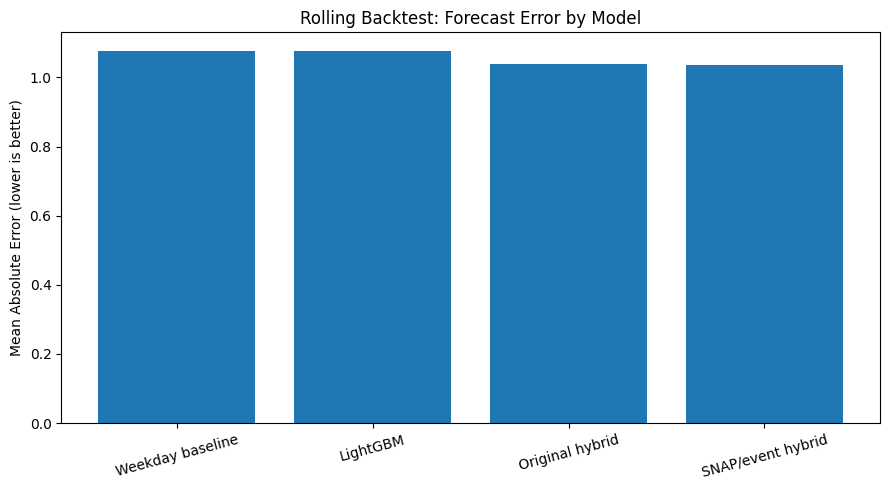

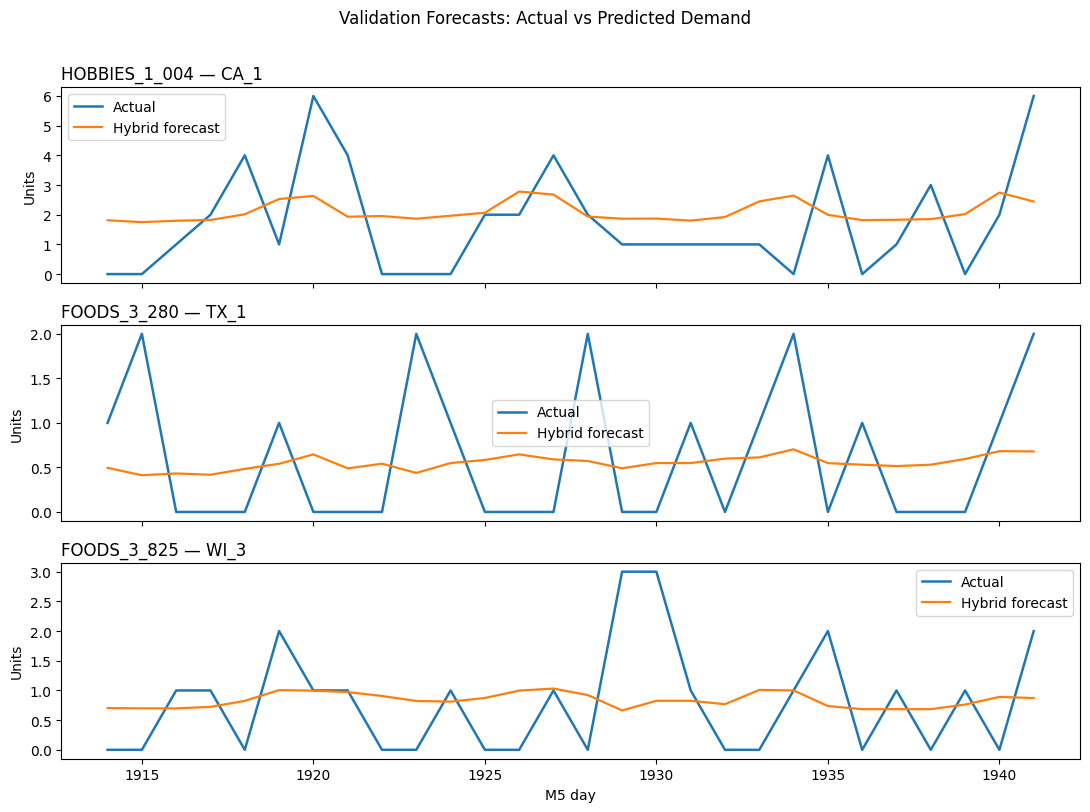

Figures saved to: /content/drive/MyDrive/Walmart_M5_Forecasting/data/processed/figures
Created:
- rolling_backtest_mae.png
- validation_forecast_examples.png
- final_28_day_forecast.png


In [52]:


# Save figures in a dedicated project folder.
FIGURE_DIR = Processed / "figures"
FIGURE_DIR.mkdir(parents=True, exist_ok=True)

# ------------------------------------------------------------
# Figure 1: Rolling backtest model comparison
# ------------------------------------------------------------
comparison = pd.DataFrame({
    "Model": [
        "Weekday baseline",
        "LightGBM",
        "Original hybrid",
        "SNAP/event hybrid",
    ],
    "MAE": [1.0755, 1.0766, 1.0385, 1.0370],
    "WAPE (%)": [77.8535, 77.9328, 75.1799, 75.07],
})

fig, ax = plt.subplots(figsize=(9, 5))
ax.bar(comparison["Model"], comparison["MAE"])
ax.set_ylabel("Mean Absolute Error (lower is better)")
ax.set_title("Rolling Backtest: Forecast Error by Model")
ax.tick_params(axis="x", rotation=15)
fig.tight_layout()
fig.savefig(FIGURE_DIR / "rolling_backtest_mae.png", dpi=200)
plt.show()


# ------------------------------------------------------------
# Figure 2: Actual vs predicted demand for selected series
# ------------------------------------------------------------
# Select a few of the more active series using validation history.
validation_history = all_actual[:, :1913]
active_share = (validation_history > 0).mean(axis=1)

# Choose three active series with different activity levels.
candidate_indices = np.flatnonzero(active_share > 0.30)
if len(candidate_indices) >= 3:
    positions = np.linspace(
        0, len(candidate_indices) - 1, 3, dtype=int
    )
    selected_indices = candidate_indices[positions]
else:
    selected_indices = np.argsort(active_share)[-3:]

actual_days = np.arange(1914, 1942)

fig, axes = plt.subplots(
    len(selected_indices), 1, figsize=(11, 8), sharex=True
)
axes = np.atleast_1d(axes)

for ax, idx in zip(axes, selected_indices):
    actual = all_actual[idx, 1913:1941]
    predicted = validation_forecast[idx]

    item = sales_val.iloc[idx]["item_id"]
    store = sales_val.iloc[idx]["store_id"]

    ax.plot(actual_days, actual, label="Actual", linewidth=1.8)
    ax.plot(actual_days, predicted, label="Hybrid forecast", linewidth=1.6)
    ax.set_title(f"{item} — {store}", loc="left")
    ax.set_ylabel("Units")
    ax.legend()

axes[-1].set_xlabel("M5 day")
fig.suptitle(
    "Validation Forecasts: Actual vs Predicted Demand",
    y=1.01,
)
fig.tight_layout()
fig.savefig(FIGURE_DIR / "validation_forecast_examples.png", dpi=200)
plt.show()


print("Figures saved to:", FIGURE_DIR)
print("Created:")
for filename in [
    "rolling_backtest_mae.png",
    "validation_forecast_examples.png",
    "final_28_day_forecast.png",
]:
    print("-", filename)

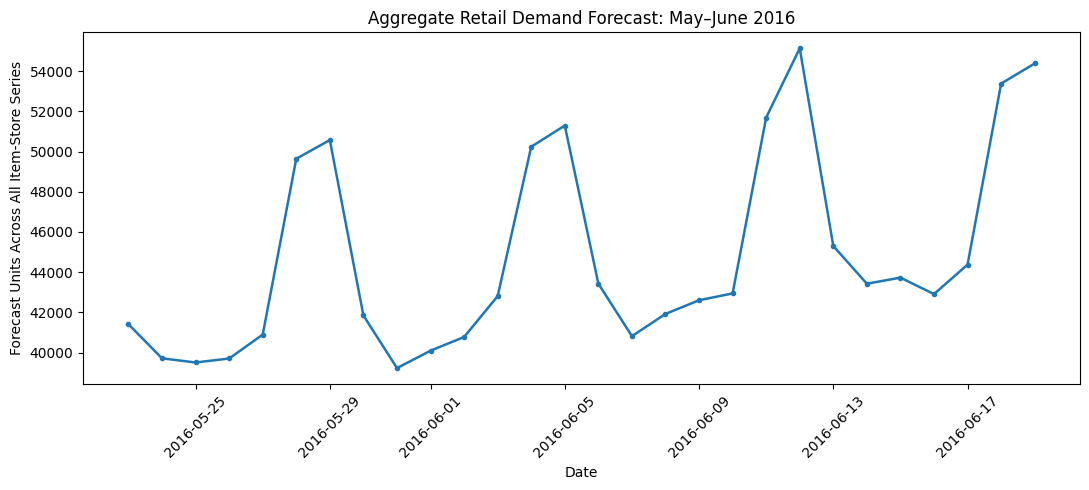

Forecast period: 23 May 2016 to 19 June 2016


In [51]:
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np

FIGURE_DIR = Processed / "figures"
FIGURE_DIR.mkdir(parents=True, exist_ok=True)

# Map the final 28 forecast days to their real calendar dates
evaluation_days = [f"d_{day}" for day in range(1942, 1970)]

date_lookup = (
    calendar.set_index("d")["date"]
    .pipe(pd.to_datetime)
)

evaluation_dates = date_lookup.loc[evaluation_days]

# Aggregate forecasted units across all item-store series
total_daily_forecast = evaluation_forecast.sum(axis=0)

fig, ax = plt.subplots(figsize=(11, 5))

ax.plot(
    evaluation_dates,
    total_daily_forecast,
    marker="o",
    markersize=3,
    linewidth=1.8
)

ax.set_title("Aggregate Retail Demand Forecast: May–June 2016")
ax.set_xlabel("Date")
ax.set_ylabel("Forecast Units Across All Item-Store Series")

ax.tick_params(axis="x", rotation=45)
fig.tight_layout()

fig.savefig(
    FIGURE_DIR / "final_28_day_forecast.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()

print(
    "Forecast period:",
    evaluation_dates.min().strftime("%d %B %Y"),
    "to",
    evaluation_dates.max().strftime("%d %B %Y")
)